# 🏛️ Nhận diện chữ số La Mã viết tay (I → X) với **VGG16 tự xây dựng từ đầu**

**Dataset:** [DeepLearning.AI – Data-Centric AI Competition](https://https-deeplearning-ai.github.io/data-centric-comp/) — ảnh chữ số La Mã viết tay từ `i` đến `x` (10 lớp).

**Mục tiêu notebook**
- Tự cài đặt kiến trúc **VGG16** bằng các layer cơ bản (`Conv2D`, `MaxPooling2D`, `Dense`, …) — **không dùng** `tf.keras.applications.VGG16`, **không dùng pretrained weights**.
- Huấn luyện theo **4 stage** cải tiến dần, so sánh kết quả từng stage với nhau.
- Báo cáo **accuracy chi tiết**: Train / Validation / Label Book, per-class accuracy, classification report, confusion matrix, các cặp lớp hay nhầm, ảnh dự đoán sai.

| Stage | Nội dung | Mục đích |
|---|---|---|
| **1 – Baseline** | VGG16 “thuần” (không BN, không Dropout, không augmentation) | Mốc so sánh |
| **2 – Regularization** | + BatchNorm + Dropout + L2 | Giảm overfit, train ổn định |
| **3 – Augmentation** | + Data augmentation (xoay, dịch, zoom, contrast) | Tăng khả năng tổng quát hoá |
| **4 – Optimization** | + AdamW + Cosine LR + Label smoothing + Class weights + EarlyStopping | Mô hình tốt nhất |

> ⚠️ **Lưu ý:** Không dùng `RandomFlip` (lật ngang) vì lật `iv` ↔ `vi`, `ix` ↔ `xi` sẽ **làm sai nhãn**.

---
**Mục lục**
1. Cài đặt & import thư viện
2. Tải dữ liệu
3. Khám phá dữ liệu (EDA)
4. Pipeline dữ liệu `tf.data` & Augmentation
5. Xây dựng VGG16 từ đầu
6. Hàm tiện ích train / đánh giá
7. Stage 1 → Stage 4
8. So sánh các stage
9. Phân tích chi tiết mô hình tốt nhất
10. Inference & lưu mô hình
11. Kết luận

## 1. ⚙️ Cài đặt & Import thư viện
> Trên Colab: `Runtime → Change runtime type → GPU (T4)` để train nhanh hơn.

In [1]:
import os, sys, time, glob, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks, optimizers, losses

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")

# ---------------- Reproducibility ----------------
SEED = 42
def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
set_seed()

print(f"Python      : {sys.version.split()[0]}")
print(f"TensorFlow  : {tf.__version__}")
print(f"NumPy       : {np.__version__}")
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for g in gpus:
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except Exception:
            pass
    print(f"✅ GPU      : {[g.name for g in gpus]}")
else:
    print("⚠️  Không tìm thấy GPU – sẽ train bằng CPU (chậm).")

Python      : 3.13.16
TensorFlow  : 2.21.0
NumPy       : 2.4.6
✅ GPU      : ['/physical_device:GPU:0']


## 2. 📥 Tải dữ liệu
Tự động clone repo (nếu chạy trên Colab) và giải nén `data.tar.gz`, `label_book.tar.gz`.

Cấu trúc sau khi giải nén:
```
data/
 ├── train/{i, ii, iii, iv, v, vi, vii, viii, ix, x}/*.png
 └── val/  {i, ii, iii, iv, v, vi, vii, viii, ix, x}/*.png
label_book/{i, ii, ..., x}/*.png      ← tập test nhỏ (≈5 ảnh / lớp)
```

In [2]:
import sys
import os

try:
    import google.colab
    IN_COLAB = True
    print("🚀 Đang chạy trên Google Colab")
except ImportError:
    IN_COLAB = False
    print("💻 Đang chạy trên Local Machine")

if IN_COLAB:
    if os.path.exists("/content/deeplearningai-data-centric-competition"):
        os.chdir("/content/deeplearningai-data-centric-competition")
    elif not os.path.exists("data"):
        os.system("git clone https://github.com/Nov05/deeplearningai-data-centric-competition.git")
        if os.path.exists("deeplearningai-data-centric-competition"):
            os.chdir("deeplearningai-data-centric-competition")

# Giải nén data và label_book nếu chưa có
import tarfile
if not os.path.exists("data") and os.path.exists("original/data.tar.gz"):
    with tarfile.open("original/data.tar.gz", "r:gz") as tar:
        tar.extractall(".")
    print("✅ Đã giải nén dữ liệu data thành công.")

if not os.path.exists("label_book") and os.path.exists("original/label_book.tar.gz"):
    with tarfile.open("original/label_book.tar.gz", "r:gz") as tar:
        tar.extractall(".")
    print("✅ Đã giải nén dữ liệu label_book thành công.")

import glob
raw_count = len(glob.glob("data/**/*.png", recursive=True))
print(f"✅ Dữ liệu gốc: Tìm thấy {raw_count} ảnh.")
assert raw_count > 0, "LỖI: Chưa có ảnh trong thư mục 'data/'!"

🚀 Đang chạy trên Google Colab
✅ Đã giải nén dữ liệu data thành công.
✅ Dữ liệu gốc: Tìm thấy 2880 ảnh.


In [3]:
# ---------------- Đường dẫn & danh sách lớp ----------------
TRAIN_DIR      = "data/train"
VAL_DIR        = "data/val"
LABEL_BOOK_DIR = "label_book"

CLASS_NAMES = ["i", "ii", "iii", "iv", "v", "vi", "vii", "viii", "ix", "x"]
NUM_CLASSES = len(CLASS_NAMES)
ROMAN_TO_INT = {c: i + 1 for i, c in enumerate(CLASS_NAMES)}

for d in [TRAIN_DIR, VAL_DIR, LABEL_BOOK_DIR]:
    status = "✅" if os.path.isdir(d) else "❌"
    print(f"{status} {d}")
print(f"\nSố lớp: {NUM_CLASSES} → {CLASS_NAMES}")

✅ data/train
✅ data/val
✅ label_book

Số lớp: 10 → ['i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x']


## 3. 🔍 Khám phá dữ liệu (EDA)
### 3.1 Số lượng ảnh theo lớp & theo tập

In [4]:
def count_images(root):
    return {c: len(glob.glob(os.path.join(root, c, "*.png"))) for c in CLASS_NAMES}

df_count = pd.DataFrame({
    "train":      count_images(TRAIN_DIR),
    "val":        count_images(VAL_DIR),
    "label_book": count_images(LABEL_BOOK_DIR),
})
df_count.index.name = "class"
df_count["total"] = df_count.sum(axis=1)
df_count.loc["TOTAL"] = df_count.sum()

print("📊 Phân bố số lượng ảnh:")
display(df_count)

n_train, n_val, n_lb = df_count.loc["TOTAL", ["train", "val", "label_book"]]
print(f"\nTrain: {n_train} | Val: {n_val} | Label Book: {n_lb}")
print(f"Tỉ lệ Train/Val: {n_train/(n_train+n_val)*100:.1f}% / {n_val/(n_train+n_val)*100:.1f}%")

📊 Phân bố số lượng ảnh:


,train,val,label_book,total
class,,,,
i,261,82,5,348
ii,157,81,5,243
iii,186,79,6,271
iv,281,84,5,370
v,196,83,6,285
vi,181,82,5,268
vii,193,77,5,275
viii,199,83,5,287
ix,234,81,5,320



Train: 2067 | Val: 813 | Label Book: 52
Tỉ lệ Train/Val: 71.8% / 28.2%


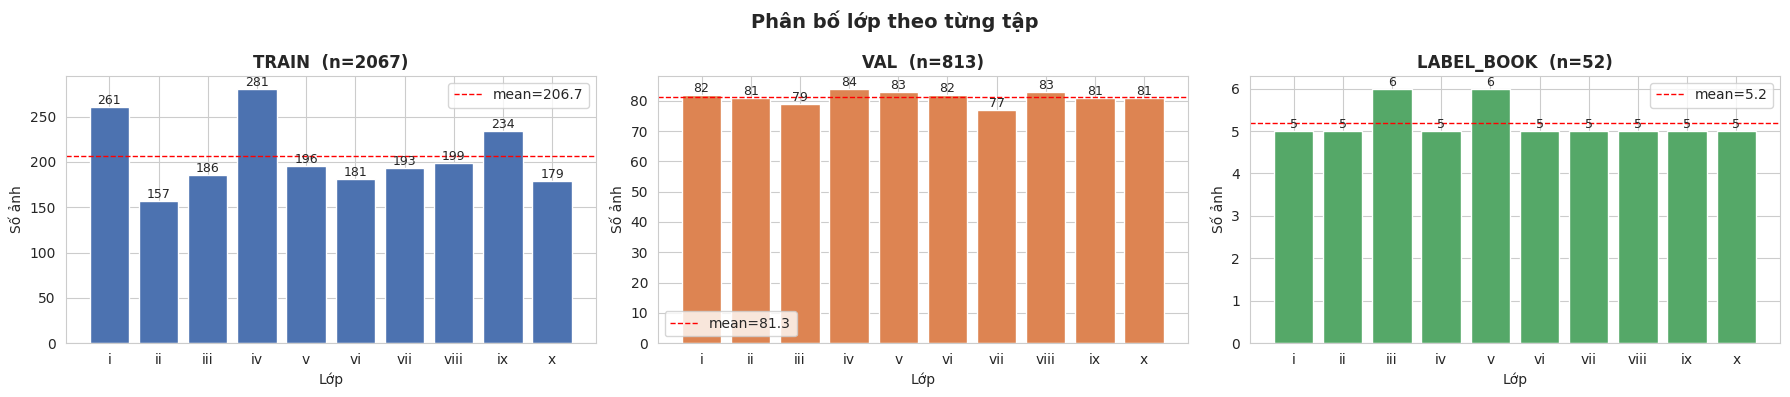

Imbalance ratio (max/min) trên train: 1.79


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, split, color in zip(axes, ["train", "val", "label_book"], ["#4C72B0", "#DD8452", "#55A868"]):
    vals = df_count.loc[CLASS_NAMES, split]
    bars = ax.bar(CLASS_NAMES, vals, color=color)
    ax.bar_label(bars, fontsize=9)
    ax.axhline(vals.mean(), color="red", ls="--", lw=1, label=f"mean={vals.mean():.1f}")
    ax.set_title(f"{split.upper()}  (n={vals.sum()})", fontweight="bold")
    ax.set_xlabel("Lớp"); ax.set_ylabel("Số ảnh"); ax.legend()
plt.suptitle("Phân bố lớp theo từng tập", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

imb = df_count.loc[CLASS_NAMES, "train"]
print(f"Imbalance ratio (max/min) trên train: {imb.max()/imb.min():.2f}")

### 3.2 Ảnh mẫu của từng lớp

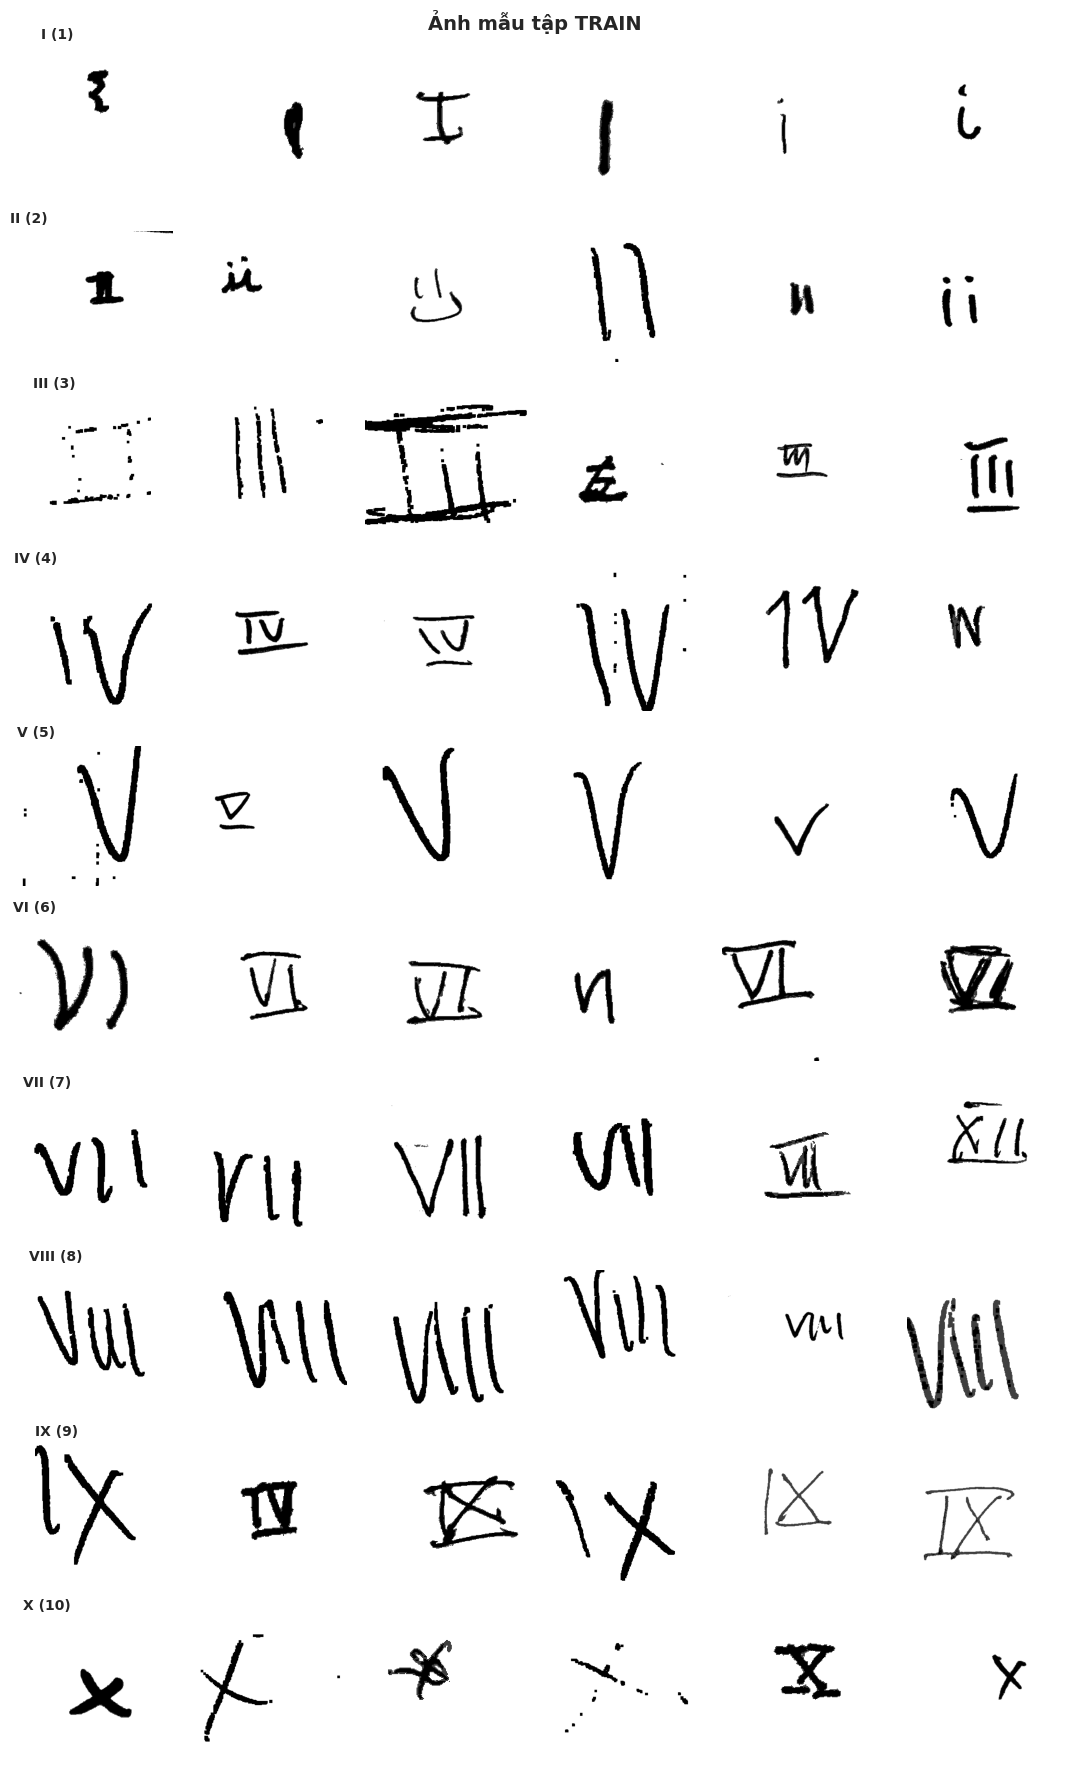

In [6]:
N_SAMPLES = 6
fig, axes = plt.subplots(NUM_CLASSES, N_SAMPLES, figsize=(N_SAMPLES * 1.8, NUM_CLASSES * 1.8))
for r, c in enumerate(CLASS_NAMES):
    files = sorted(glob.glob(os.path.join(TRAIN_DIR, c, "*.png")))
    picks = random.sample(files, min(N_SAMPLES, len(files)))
    for k in range(N_SAMPLES):
        ax = axes[r, k]; ax.axis("off")
        if k < len(picks):
            ax.imshow(Image.open(picks[k]).convert("L"), cmap="gray")
        if k == 0:
            ax.set_title(f"{c.upper()} ({ROMAN_TO_INT[c]})", fontsize=10, loc="left", fontweight="bold")
plt.suptitle("Ảnh mẫu tập TRAIN", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### 3.3 Thống kê kích thước & cường độ điểm ảnh
Ảnh gốc có kích thước **không đồng nhất**, ảnh xám (mode `L`), nền trắng – nét đen ⇒ cần resize về kích thước cố định.

📐 Thống kê kích thước ảnh:


split            label_book    train     val
width     count       52.00  2067.00  813.00
          mean       299.15   275.99  285.91
          std        101.72    88.77   62.59
          min        162.00   121.00  132.00
          25%        240.00   231.00  249.00
          50%        259.50   259.00  286.00
          75%        363.25   291.00  302.00
          max        726.00  1260.00  693.00
height    count       52.00  2067.00  813.00
          mean       246.50   253.56  268.02
          std         65.15    68.73   56.00
          min        121.00    88.00  120.00
          25%        200.25   213.00  236.00
          50%        253.00   253.00  270.00
          75%        281.00   286.00  297.00
          max        402.00   616.00  616.00
aspect    count       52.00  2067.00  813.00
          mean         1.24     1.11    1.08
          std          0.29     0.25    0.19
          min          0.78     0.41    0.46
          25%          0.98     0.95    0.97
          50%          1.24     1.07    1.06
          75%          1.43     1.23    1.16
          max          1.82     3.23    1.94
mean_px   count       52.00  2067.00  813.00
          mean       240.01   241.00  243.49
          std          8.21     7.01    8.36
          min        209.06   162.27  128.44
          25%        236.47   237.20  241.32
          50%        241.57   242.19  245.57
          75%        245.35   245.70  248.67
          max        252.98   255.00  253.75
ink_ratio count       52.00  2067.00  813.00
          mean         0.07     0.07    0.05
          std          0.04     0.03    0.04
          min          0.01     0.00    0.01
          25%          0.04     0.04    0.03
          50%          0.06     0.06    0.04
          75%          0.08     0.08    0.06
          max          0.18     0.48    0.66

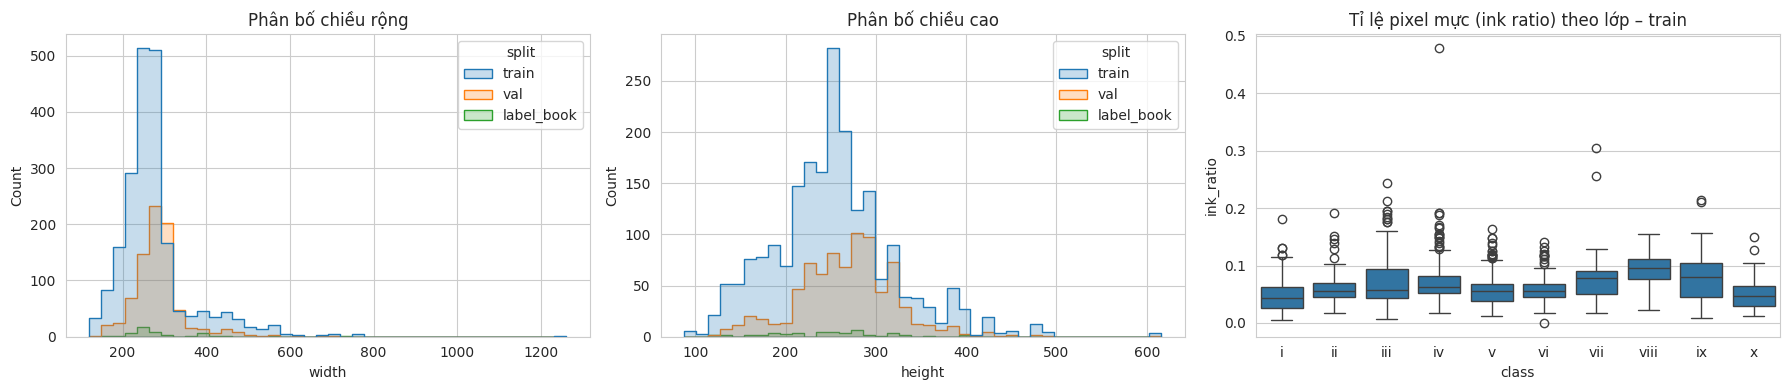

In [7]:
records = []
for split, root in [("train", TRAIN_DIR), ("val", VAL_DIR), ("label_book", LABEL_BOOK_DIR)]:
    for c in CLASS_NAMES:
        for f in glob.glob(os.path.join(root, c, "*.png")):
            with Image.open(f) as im:
                w, h = im.size
                arr = np.asarray(im.convert("L"), dtype=np.float32)
            records.append({"split": split, "class": c, "width": w, "height": h,
                            "aspect": w / h, "mean_px": arr.mean(), "ink_ratio": (arr < 128).mean()})
df_img = pd.DataFrame(records)

print("📐 Thống kê kích thước ảnh:")
display(df_img.groupby("split")[["width", "height", "aspect", "mean_px", "ink_ratio"]].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(data=df_img, x="width",  hue="split", bins=40, ax=axes[0], element="step")
sns.histplot(data=df_img, x="height", hue="split", bins=40, ax=axes[1], element="step")
sns.boxplot(data=df_img[df_img.split == "train"], x="class", y="ink_ratio", order=CLASS_NAMES, ax=axes[2])
axes[0].set_title("Phân bố chiều rộng"); axes[1].set_title("Phân bố chiều cao")
axes[2].set_title("Tỉ lệ pixel mực (ink ratio) theo lớp – train")
plt.tight_layout(); plt.show()

## 4. 🔄 Pipeline dữ liệu `tf.data` & Data Augmentation
- Resize về **64×64**, ảnh xám **1 kênh** (VGG16 tự build nên không bắt buộc 224×224×3).
- Chuẩn hoá `[0, 255] → [0, 1]` được đặt **bên trong model** (`Rescaling`) để model tự chứa toàn bộ tiền xử lý.
- Tập `train_eval_ds` = train **không shuffle, không augmentation** → dùng để đo Train Accuracy chính xác.

In [8]:
IMG_SIZE    = 64
IMG_SHAPE   = (IMG_SIZE, IMG_SIZE, 1)
BATCH_SIZE  = 32
AUTOTUNE    = tf.data.AUTOTUNE

def load_ds(directory, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="categorical",
        class_names=CLASS_NAMES,
        color_mode="grayscale",
        batch_size=BATCH_SIZE,
        image_size=(IMG_SIZE, IMG_SIZE),
        shuffle=shuffle,
        seed=SEED,
    )

print("🔹 Train:");      train_raw      = load_ds(TRAIN_DIR, shuffle=True)
print("🔹 Train-eval:"); train_eval_raw = load_ds(TRAIN_DIR, shuffle=False)
print("🔹 Val:");        val_raw        = load_ds(VAL_DIR, shuffle=False)
print("🔹 Label book:"); lb_raw         = load_ds(LABEL_BOOK_DIR, shuffle=False)

train_ds      = train_raw.cache().prefetch(AUTOTUNE)
train_eval_ds = train_eval_raw.cache().prefetch(AUTOTUNE)
val_ds        = val_raw.cache().prefetch(AUTOTUNE)
lb_ds         = lb_raw.cache().prefetch(AUTOTUNE)

xb, yb = next(iter(train_ds))
print(f"\nBatch ảnh : {xb.shape}, dtype={xb.dtype}, min={xb.numpy().min():.0f}, max={xb.numpy().max():.0f}")
print(f"Batch nhãn: {yb.shape} (one-hot)")

🔹 Train:
Found 2067 files belonging to 10 classes.
🔹 Train-eval:
Found 2067 files belonging to 10 classes.
🔹 Val:
Found 813 files belonging to 10 classes.
🔹 Label book:
Found 52 files belonging to 10 classes.

Batch ảnh : (32, 64, 64, 1), dtype=<dtype: 'float32'>, min=0, max=255
Batch nhãn: (32, 10) (one-hot)


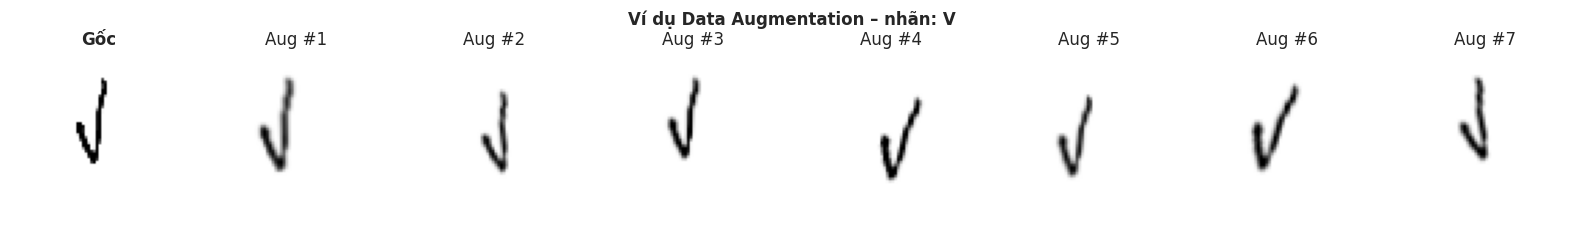

In [9]:
# ---------------- Data Augmentation (chỉ dùng cho Stage 3, 4) ----------------
# Nền ảnh là trắng (255) → fill_value=255 để vùng trống sau khi xoay/dịch vẫn là nền trắng.
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05, fill_mode="constant", fill_value=255.0),               # ±18°
    layers.RandomTranslation(0.10, 0.10, fill_mode="constant", fill_value=255.0),
    layers.RandomZoom((-0.15, 0.10), fill_mode="constant", fill_value=255.0),
    layers.RandomContrast(0.2),
], name="data_augmentation")
# KHÔNG dùng RandomFlip("horizontal") → iv ↔ vi, ix ↔ xi sẽ bị đổi nghĩa!

def make_aug_ds(ds_raw):
    return (ds_raw.cache()
                  .map(lambda x, y: (tf.clip_by_value(data_augmentation(x, training=True), 0., 255.), y),
                       num_parallel_calls=AUTOTUNE)
                  .prefetch(AUTOTUNE))

train_aug_ds = make_aug_ds(train_raw)

# Minh hoạ augmentation
sample_img = xb[0:1]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(sample_img[0, ..., 0], cmap="gray"); axes[0].set_title("Gốc", fontweight="bold")
for i in range(1, 8):
    aug = tf.clip_by_value(data_augmentation(sample_img, training=True), 0, 255)
    axes[i].imshow(aug[0, ..., 0], cmap="gray", vmin=0, vmax=255); axes[i].set_title(f"Aug #{i}")
for ax in axes: ax.axis("off")
plt.suptitle(f"Ví dụ Data Augmentation – nhãn: {CLASS_NAMES[int(np.argmax(yb[0]))].upper()}", fontweight="bold")
plt.tight_layout(); plt.show()

## 5. 🧱 Xây dựng VGG16 từ đầu (from scratch)

Kiến trúc VGG16 gốc (Simonyan & Zisserman, 2014) gồm **13 Conv + 3 FC = 16 layer có trọng số**:

| Block | Layers | Filters | Output (input 64×64) |
|---|---|---|---|
| Block 1 | 2 × Conv3×3 + MaxPool | 64  | 32×32×64 |
| Block 2 | 2 × Conv3×3 + MaxPool | 128 | 16×16×128 |
| Block 3 | 3 × Conv3×3 + MaxPool | 256 | 8×8×256 |
| Block 4 | 3 × Conv3×3 + MaxPool | 512 | 4×4×512 |
| Block 5 | 3 × Conv3×3 + MaxPool | 512 | 2×2×512 |
| Classifier | Flatten → FC → FC → FC(10, softmax) | – | 10 |

**Điều chỉnh cho bài toán nhỏ:** FC gốc 4096 neuron → **512 neuron** (dữ liệu chỉ ~2–3k ảnh, FC 4096 sẽ có hàng chục triệu tham số và overfit nặng).
Tuỳ chọn `use_bn`, `dropout`, `l2` cho phép bật/tắt regularization theo từng stage.

In [10]:
# (filters, số lớp conv) cho 5 block của VGG16
VGG16_CONFIG = [(64, 2), (128, 2), (256, 3), (512, 3), (512, 3)]

def conv_bn_relu(x, filters, use_bn, l2, name):
    reg = regularizers.l2(l2) if l2 > 0 else None
    x = layers.Conv2D(filters, kernel_size=3, padding="same",
                      use_bias=not use_bn,                 # BN đã có bias (beta)
                      kernel_initializer="he_normal",
                      kernel_regularizer=reg, name=name)(x)
    if use_bn:
        x = layers.BatchNormalization(name=name + "_bn")(x)
    x = layers.Activation("relu", name=name + "_relu")(x)
    return x

def build_vgg16(input_shape=IMG_SHAPE, num_classes=NUM_CLASSES,
                use_bn=False, dropout=0.0, l2=0.0, fc_units=512, name="VGG16_scratch"):
    """VGG16 tự xây dựng hoàn toàn từ các layer cơ bản – KHÔNG dùng tf.keras.applications."""
    inputs = layers.Input(shape=input_shape, name="input_image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inputs)

    # ---------- Feature extractor: 13 Conv ----------
    for b, (filters, n_conv) in enumerate(VGG16_CONFIG, start=1):
        for c in range(1, n_conv + 1):
            x = conv_bn_relu(x, filters, use_bn, l2, name=f"block{b}_conv{c}")
        x = layers.MaxPooling2D(pool_size=2, strides=2, name=f"block{b}_pool")(x)

    # ---------- Classifier: 3 FC ----------
    reg = regularizers.l2(l2) if l2 > 0 else None
    x = layers.Flatten(name="flatten")(x)
    for i in (1, 2):
        x = layers.Dense(fc_units, kernel_initializer="he_normal", kernel_regularizer=reg, name=f"fc{i}")(x)
        if use_bn:
            x = layers.BatchNormalization(name=f"fc{i}_bn")(x)
        x = layers.Activation("relu", name=f"fc{i}_relu")(x)
        if dropout > 0:
            x = layers.Dropout(dropout, name=f"fc{i}_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

    return models.Model(inputs, outputs, name=name)

In [11]:
# Kiểm tra kiến trúc
_demo = build_vgg16(use_bn=True, dropout=0.5, name="VGG16_demo")
_demo.summary()

# Thống kê số tham số theo block
rows = []
for blk in [f"block{i}" for i in range(1, 6)] + ["fc1", "fc2", "predictions"]:
    p = sum(l.count_params() for l in _demo.layers if l.name.startswith(blk))
    rows.append({"block": blk, "params": p})
df_params = pd.DataFrame(rows)
df_params["%"] = (df_params.params / df_params.params.sum() * 100).round(2)
display(df_params)
n_conv = sum(isinstance(l, layers.Conv2D) for l in _demo.layers)
n_fc   = sum(isinstance(l, layers.Dense)  for l in _demo.layers)
print(f"✅ Số layer có trọng số: {n_conv} Conv + {n_fc} FC = {n_conv + n_fc} (VGG16)")
print(f"✅ Tổng tham số: {_demo.count_params():,}")
del _demo

Model: "VGG16_demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 64, 64, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1_bn                 │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1_relu (Activation)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2_bn                 │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2_relu (Activation)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1_bn                 │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1_relu (Activation)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2_bn                 │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2_relu (Activation)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1_bn                 │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1_relu (Activation)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 16, 16, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2_bn                 │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2_relu (Activation)  │ (None, 16, 16, 256)    │             

 Total params: 16,047,178 (61.22 MB)

 Trainable params: 16,036,682 (61.18 MB)

 Non-trainable params: 10,496 (41.00 KB)

,block,params,%
0,block1,37952,0.24
1,block2,222208,1.38
2,block3,1477632,9.21
3,block4,5904384,36.79
4,block5,7084032,44.15
5,fc1,1051136,6.55
6,fc2,264704,1.65
7,predictions,5130,0.03


✅ Số layer có trọng số: 13 Conv + 3 FC = 16 (VGG16)
✅ Tổng tham số: 16,047,178


## 6. 🛠️ Hàm tiện ích: train, đánh giá, vẽ biểu đồ
- **Checkpoint**: lưu trọng số có `val_accuracy` cao nhất → `best_vgg16_stage{N}.weights.h5`.
- **Đánh giá**: Loss được tính lại bằng *Categorical Cross-Entropy chuẩn* (không label smoothing) để **so sánh công bằng** giữa các stage.

In [12]:
RESULTS   = {}   # lưu kết quả từng stage
HISTORIES = {}

def train_stage(stage_id, model, train_data, epochs, optimizer, loss_fn,
                extra_callbacks=None, class_weight=None):
    ckpt_path = f"best_vgg16_stage{stage_id}.weights.h5"
    cbs = [
        callbacks.ModelCheckpoint(ckpt_path, monitor="val_accuracy", mode="max",
                                  save_best_only=True, save_weights_only=True, verbose=0),
        callbacks.CSVLogger(f"history_stage{stage_id}.csv"),
    ] + (extra_callbacks or [])

    model.compile(optimizer=optimizer, loss=loss_fn,
                  metrics=["accuracy", tf.keras.metrics.TopKCategoricalAccuracy(k=2, name="top2_acc")])

    print(f"🚀 Bắt đầu train Stage {stage_id} – {epochs} epochs tối đa")
    t0 = time.time()
    history = model.fit(train_data, validation_data=val_ds, epochs=epochs,
                        callbacks=cbs, class_weight=class_weight, verbose=2)
    train_time = time.time() - t0

    model.load_weights(ckpt_path)      # khôi phục trọng số tốt nhất
    HISTORIES[stage_id] = history.history
    return history, train_time, ckpt_path


def predict_ds(model, ds, return_images=False):
    """Trả về y_true, y_prob (và ảnh nếu cần) – duyệt cùng lúc nên luôn khớp thứ tự."""
    ys, ps, xs = [], [], []
    for x, y in ds:
        ps.append(model(x, training=False).numpy())
        ys.append(np.argmax(y.numpy(), axis=1))
        if return_images: xs.append(x.numpy())
    y_true, y_prob = np.concatenate(ys), np.concatenate(ps)
    return (y_true, y_prob, np.concatenate(xs)) if return_images else (y_true, y_prob)


def metrics_from_pred(y_true, y_prob):
    y_pred = y_prob.argmax(1)
    ce = -np.mean(np.log(np.clip(y_prob[np.arange(len(y_true)), y_true], 1e-7, 1.0)))
    top2 = np.mean([t in np.argsort(p)[-2:] for t, p in zip(y_true, y_prob)])
    return {"acc": accuracy_score(y_true, y_pred), "loss": ce, "top2": top2,
            "f1_macro": f1_score(y_true, y_pred, average="macro"),
            "n_correct": int((y_pred == y_true).sum()), "n_total": len(y_true)}


def evaluate_stage(stage_id, stage_name, model, history, train_time, ckpt_path):
    tr = metrics_from_pred(*predict_ds(model, train_eval_ds))
    va = metrics_from_pred(*predict_ds(model, val_ds))
    lb = metrics_from_pred(*predict_ds(model, lb_ds))
    hist = history.history
    best_ep = int(np.argmax(hist["val_accuracy"])) + 1

    print("=" * 60)
    print(f"📊 KẾT QUẢ STAGE {stage_id}: {stage_name}")
    print("=" * 60)
    print(f"  • Số tham số          : {model.count_params():,}")
    print(f"  • Epoch tốt nhất      : {best_ep}/{len(hist['loss'])}")
    print(f"  • Thời gian train     : {train_time/60:.1f} phút ({train_time/len(hist['loss']):.1f}s/epoch)")
    print("-" * 60)
    print(f"  • Train Accuracy: {tr['acc']*100:.2f}% | Loss: {tr['loss']:.4f}  ({tr['n_correct']}/{tr['n_total']})")
    print(f"  • Validation Accuracy: {va['acc']*100:.2f}% | Loss: {va['loss']:.4f}  ({va['n_correct']}/{va['n_total']})")
    print(f"  • Label Book Accuracy: {lb['acc']*100:.2f}% | Loss: {lb['loss']:.4f}  ({lb['n_correct']}/{lb['n_total']})")
    print("-" * 60)
    print(f"  • Top-2 Acc  (Val / Label Book) : {va['top2']*100:.2f}% / {lb['top2']*100:.2f}%")
    print(f"  • Macro-F1   (Val / Label Book) : {va['f1_macro']*100:.2f}% / {lb['f1_macro']*100:.2f}%")
    print(f"  • Generalization gap (Train − Val): {(tr['acc'] - va['acc'])*100:+.2f}%")
    print("=" * 60)
    print(f"✅ Đã lưu trọng số mô hình tốt nhất: {ckpt_path}")

    RESULTS[stage_id] = {
        "Stage": f"Stage {stage_id}", "Mô tả": stage_name, "Params": model.count_params(),
        "Best epoch": best_ep, "Epochs chạy": len(hist["loss"]), "Time (phút)": round(train_time / 60, 1),
        "Train Acc": tr["acc"], "Train Loss": tr["loss"],
        "Val Acc": va["acc"], "Val Loss": va["loss"], "Val Top2": va["top2"], "Val F1": va["f1_macro"],
        "LB Acc": lb["acc"], "LB Loss": lb["loss"], "LB Top2": lb["top2"], "LB F1": lb["f1_macro"],
        "Weights": ckpt_path,
    }
    return RESULTS[stage_id]


def plot_history(history, title):
    h = history.history if hasattr(history, "history") else history
    ep = np.arange(1, len(h["loss"]) + 1)
    best = int(np.argmax(h["val_accuracy"]))
    fig, axes = plt.subplots(1, 3 if "lr" in h or "learning_rate" in h else 2, figsize=(18, 4))
    axes[0].plot(ep, h["accuracy"], label="train"); axes[0].plot(ep, h["val_accuracy"], label="val")
    axes[0].axvline(best + 1, color="red", ls="--", lw=1, label=f"best ep {best+1}: {h['val_accuracy'][best]*100:.2f}%")
    axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(ep, h["loss"], label="train"); axes[1].plot(ep, h["val_loss"], label="val")
    axes[1].axvline(best + 1, color="red", ls="--", lw=1)
    axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    lr_key = "learning_rate" if "learning_rate" in h else ("lr" if "lr" in h else None)
    if lr_key:
        axes[2].plot(ep, h[lr_key], color="green"); axes[2].set_title("Learning rate"); axes[2].set_yscale("log")
    plt.suptitle(title, fontsize=13, fontweight="bold"); plt.tight_layout(); plt.show()


def plot_confusion(y_true, y_pred, title, normalize=False, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    data = cm.astype(float) / cm.sum(1, keepdims=True).clip(min=1) if normalize else cm
    if ax is None: _, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(data, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title(title, fontweight="bold")
    return cm


def quick_report(model, stage_id):
    """Confusion matrix Val + Label Book cho một stage."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, (name, ds) in zip(axes, [("Validation", val_ds), ("Label Book", lb_ds)]):
        yt, yp = predict_ds(model, ds)
        plot_confusion(yt, yp.argmax(1), f"Stage {stage_id} – {name} (acc={accuracy_score(yt, yp.argmax(1))*100:.2f}%)", ax=ax)
    plt.tight_layout(); plt.show()

---
## 7. 🏋️ Huấn luyện

### 🔹 Stage 1 – Baseline: VGG16 thuần
- Không BatchNorm, không Dropout, không augmentation.
- Optimizer: `Adam(lr=1e-4)`, loss: `CategoricalCrossentropy`.

In [13]:
set_seed()
tf.keras.backend.clear_session()

STAGE1_EPOCHS = 40
model_s1 = build_vgg16(use_bn=False, dropout=0.0, l2=0.0, name="VGG16_stage1_baseline")

hist_s1, time_s1, ckpt_s1 = train_stage(
    stage_id=1, model=model_s1, train_data=train_ds, epochs=STAGE1_EPOCHS,
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss_fn=losses.CategoricalCrossentropy(),
)

🚀 Bắt đầu train Stage 1 – 40 epochs tối đa
Epoch 1/40
65/65 - 59s - 906ms/step - accuracy: 0.1369 - loss: 2.3469 - top2_acc: 0.2530 - val_accuracy: 0.1525 - val_loss: 2.2810 - val_top2_acc: 0.2472
Epoch 2/40
65/65 - 5s - 74ms/step - accuracy: 0.2661 - loss: 2.0122 - top2_acc: 0.4136 - val_accuracy: 0.2485 - val_loss: 1.8880 - val_top2_acc: 0.4330
Epoch 3/40
65/65 - 4s - 67ms/step - accuracy: 0.3846 - loss: 1.6521 - top2_acc: 0.5762 - val_accuracy: 0.4133 - val_loss: 1.4981 - val_top2_acc: 0.6002
Epoch 4/40
65/65 - 4s - 67ms/step - accuracy: 0.5186 - loss: 1.3586 - top2_acc: 0.7170 - val_accuracy: 0.4982 - val_loss: 1.3077 - val_top2_acc: 0.7011
Epoch 5/40
65/65 - 5s - 70ms/step - accuracy: 0.5965 - loss: 1.1295 - top2_acc: 0.7726 - val_accuracy: 0.5535 - val_loss: 1.1684 - val_top2_acc: 0.7663
Epoch 6/40
65/65 - 4s - 68ms/step - accuracy: 0.6821 - loss: 0.9385 - top2_acc: 0.8341 - val_accuracy: 0.6089 - val_loss: 1.1354 - val_top2_acc: 0.7847
Epoch 7/40
65/65 - 4s - 68ms/step - accurac

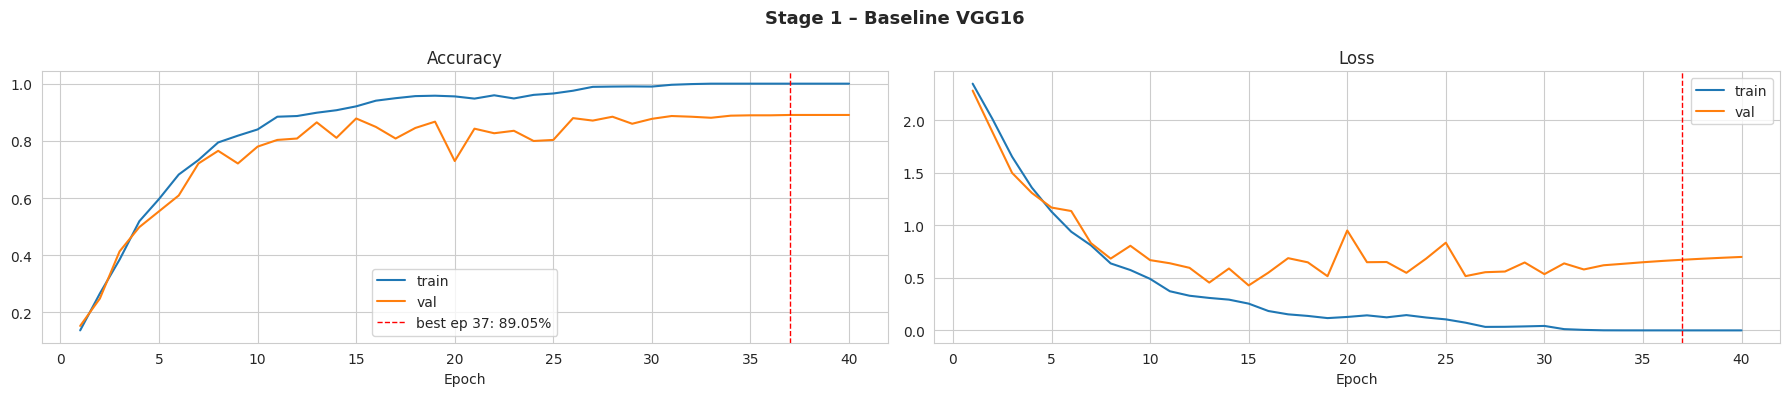

📊 KẾT QUẢ STAGE 1: Baseline VGG16 (no BN / no Dropout / no Aug)
  • Số tham số          : 16,030,410
  • Epoch tốt nhất      : 37/40
  • Thời gian train     : 3.8 phút (5.7s/epoch)
------------------------------------------------------------
  • Train Accuracy: 100.00% | Loss: 0.0001  (2067/2067)
  • Validation Accuracy: 89.05% | Loss: 0.6328  (724/813)
  • Label Book Accuracy: 86.54% | Loss: 1.0996  (45/52)
------------------------------------------------------------
  • Top-2 Acc  (Val / Label Book) : 95.33% / 94.23%
  • Macro-F1   (Val / Label Book) : 89.03% / 87.23%
  • Generalization gap (Train − Val): +10.95%
✅ Đã lưu trọng số mô hình tốt nhất: best_vgg16_stage1.weights.h5


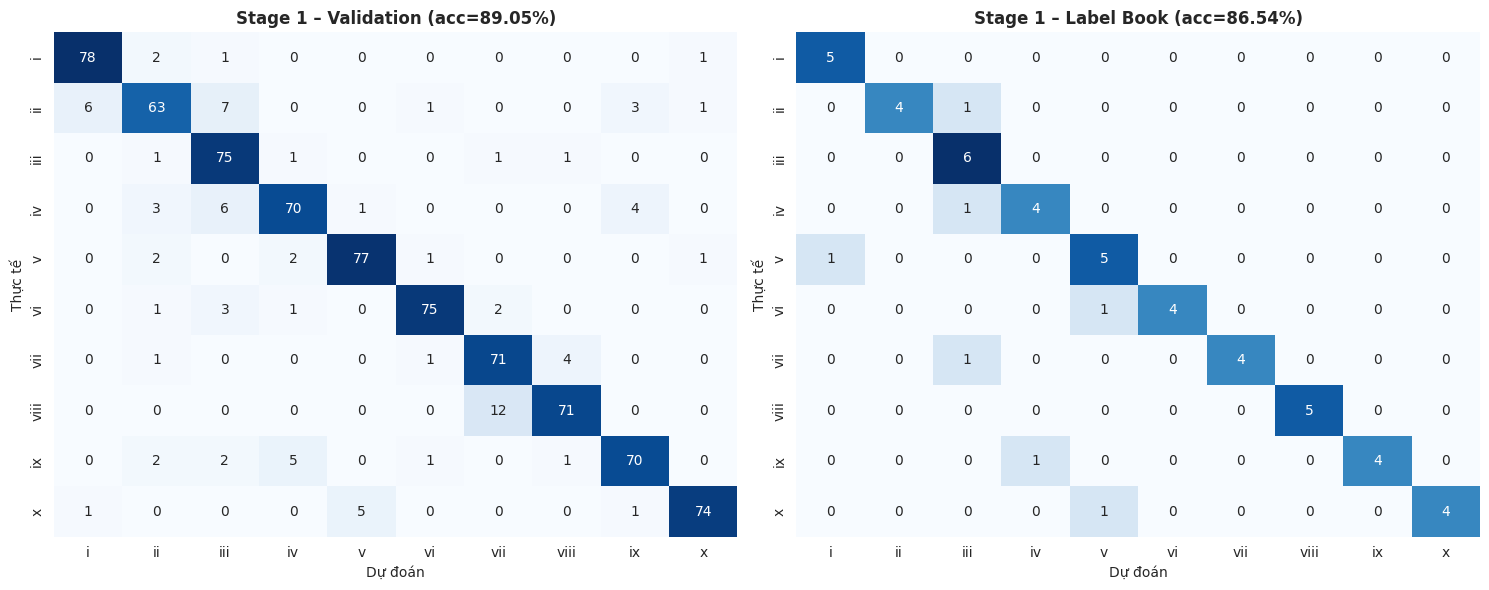

In [14]:
plot_history(hist_s1, "Stage 1 – Baseline VGG16")
res_s1 = evaluate_stage(1, "Baseline VGG16 (no BN / no Dropout / no Aug)", model_s1, hist_s1, time_s1, ckpt_s1)
quick_report(model_s1, 1)

### 🔹 Stage 2 – Thêm Regularization: BatchNorm + Dropout + L2
- **BatchNorm** sau mỗi Conv/FC → gradient ổn định, hội tụ nhanh, cho phép LR lớn hơn.
- **Dropout 0.5** ở 2 lớp FC, **L2 = 5e-4** → giảm overfit.
- `ReduceLROnPlateau` giảm LR khi `val_loss` không cải thiện.

In [15]:
set_seed()
tf.keras.backend.clear_session()

STAGE2_EPOCHS = 50
model_s2 = build_vgg16(use_bn=True, dropout=0.5, l2=5e-4, name="VGG16_stage2_bn_dropout")

hist_s2, time_s2, ckpt_s2 = train_stage(
    stage_id=2, model=model_s2, train_data=train_ds, epochs=STAGE2_EPOCHS,
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss_fn=losses.CategoricalCrossentropy(),
    extra_callbacks=[callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1)],
)

🚀 Bắt đầu train Stage 2 – 50 epochs tối đa
Epoch 1/50
65/65 - 54s - 825ms/step - accuracy: 0.1553 - loss: 8.0847 - top2_acc: 0.2825 - val_accuracy: 0.1009 - val_loss: 8.1958 - val_top2_acc: 0.2091 - learning_rate: 0.0010
Epoch 2/50
65/65 - 5s - 79ms/step - accuracy: 0.3575 - loss: 7.2375 - top2_acc: 0.5394 - val_accuracy: 0.1574 - val_loss: 11.0582 - val_top2_acc: 0.2817 - learning_rate: 0.0010
Epoch 3/50
65/65 - 9s - 146ms/step - accuracy: 0.5094 - loss: 6.5035 - top2_acc: 0.7189 - val_accuracy: 0.1218 - val_loss: 10.6769 - val_top2_acc: 0.3087 - learning_rate: 0.0010
Epoch 4/50
65/65 - 5s - 77ms/step - accuracy: 0.6318 - loss: 5.8651 - top2_acc: 0.8176 - val_accuracy: 0.5191 - val_loss: 6.5999 - val_top2_acc: 0.6839 - learning_rate: 0.0010
Epoch 5/50
65/65 - 4s - 67ms/step - accuracy: 0.7097 - loss: 5.3877 - top2_acc: 0.8587 - val_accuracy: 0.4699 - val_loss: 6.5733 - val_top2_acc: 0.7159 - learning_rate: 0.0010
Epoch 6/50
65/65 - 5s - 76ms/step - accuracy: 0.7741 - loss: 4.8776 - to

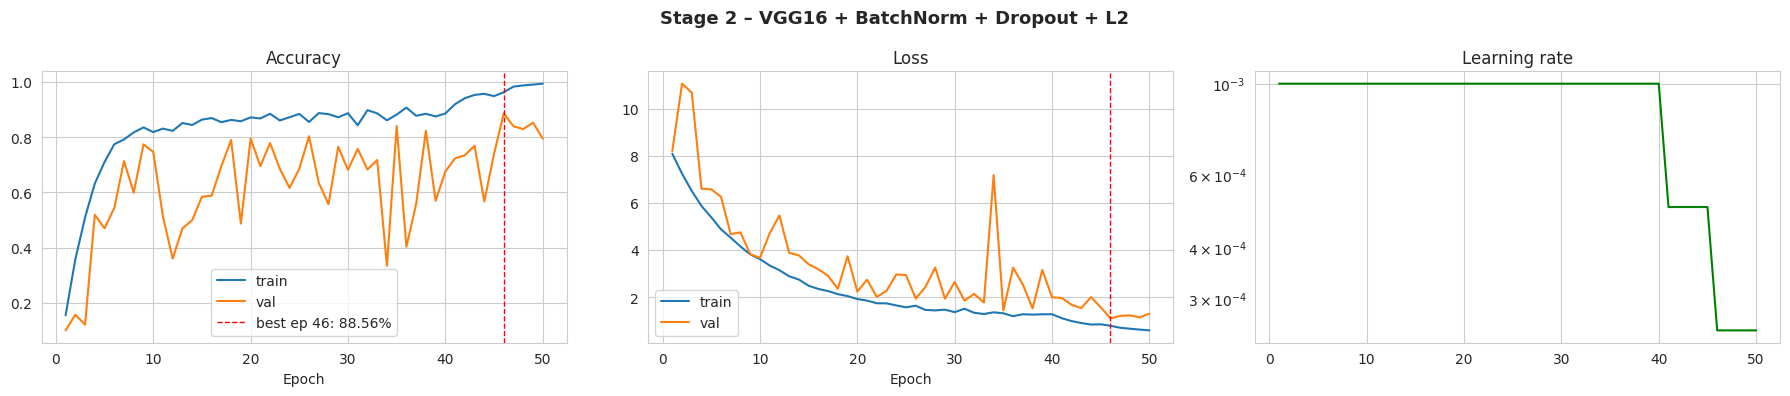

📊 KẾT QUẢ STAGE 2: VGG16 + BN + Dropout + L2
  • Số tham số          : 16,047,178
  • Epoch tốt nhất      : 46/50
  • Thời gian train     : 4.7 phút (5.6s/epoch)
------------------------------------------------------------
  • Train Accuracy: 95.45% | Loss: 0.2141  (1973/2067)
  • Validation Accuracy: 88.56% | Loss: 0.4592  (720/813)
  • Label Book Accuracy: 82.69% | Loss: 0.5720  (43/52)
------------------------------------------------------------
  • Top-2 Acc  (Val / Label Book) : 94.59% / 90.38%
  • Macro-F1   (Val / Label Book) : 88.78% / 83.76%
  • Generalization gap (Train − Val): +6.89%
✅ Đã lưu trọng số mô hình tốt nhất: best_vgg16_stage2.weights.h5


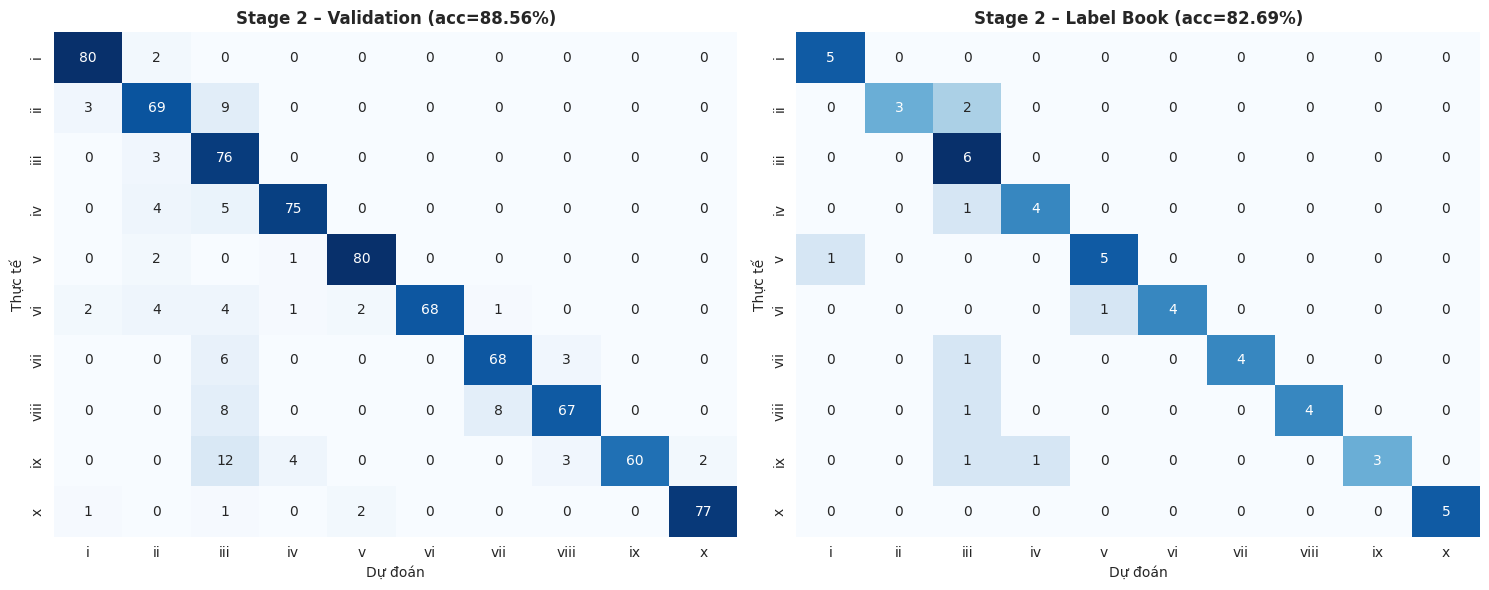

In [16]:
plot_history(hist_s2, "Stage 2 – VGG16 + BatchNorm + Dropout + L2")
res_s2 = evaluate_stage(2, "VGG16 + BN + Dropout + L2", model_s2, hist_s2, time_s2, ckpt_s2)
quick_report(model_s2, 2)

### 🔹 Stage 3 – Thêm Data Augmentation
Giữ nguyên kiến trúc Stage 2, train trên `train_aug_ds` (xoay ±18°, dịch 10%, zoom, contrast).
Augmentation mô phỏng sự đa dạng nét viết tay → giảm khoảng cách Train–Val và tăng accuracy trên Label Book.

In [17]:
set_seed()
tf.keras.backend.clear_session()

STAGE3_EPOCHS = 80
model_s3 = build_vgg16(use_bn=True, dropout=0.5, l2=5e-4, name="VGG16_stage3_augment")

hist_s3, time_s3, ckpt_s3 = train_stage(
    stage_id=3, model=model_s3, train_data=train_aug_ds, epochs=STAGE3_EPOCHS,
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss_fn=losses.CategoricalCrossentropy(),
    extra_callbacks=[callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6, verbose=1)],
)

🚀 Bắt đầu train Stage 3 – 80 epochs tối đa
Epoch 1/80
65/65 - 33s - 501ms/step - accuracy: 0.1248 - loss: 8.1252 - top2_acc: 0.2458 - val_accuracy: 0.1033 - val_loss: 56.6588 - val_top2_acc: 0.1956 - learning_rate: 0.0010
Epoch 2/80
65/65 - 5s - 82ms/step - accuracy: 0.2743 - loss: 7.3643 - top2_acc: 0.4499 - val_accuracy: 0.1661 - val_loss: 9.8993 - val_top2_acc: 0.3210 - learning_rate: 0.0010
Epoch 3/80
65/65 - 5s - 72ms/step - accuracy: 0.3445 - loss: 6.8077 - top2_acc: 0.5743 - val_accuracy: 0.1255 - val_loss: 13.1243 - val_top2_acc: 0.2288 - learning_rate: 0.0010
Epoch 4/80
65/65 - 5s - 80ms/step - accuracy: 0.3691 - loss: 6.3858 - top2_acc: 0.5941 - val_accuracy: 0.1021 - val_loss: 11.8206 - val_top2_acc: 0.2030 - learning_rate: 0.0010
Epoch 5/80
65/65 - 5s - 73ms/step - accuracy: 0.4519 - loss: 5.8909 - top2_acc: 0.6575 - val_accuracy: 0.1648 - val_loss: 7.4251 - val_top2_acc: 0.2632 - learning_rate: 0.0010
Epoch 6/80
65/65 - 6s - 87ms/step - accuracy: 0.5399 - loss: 5.3593 - to

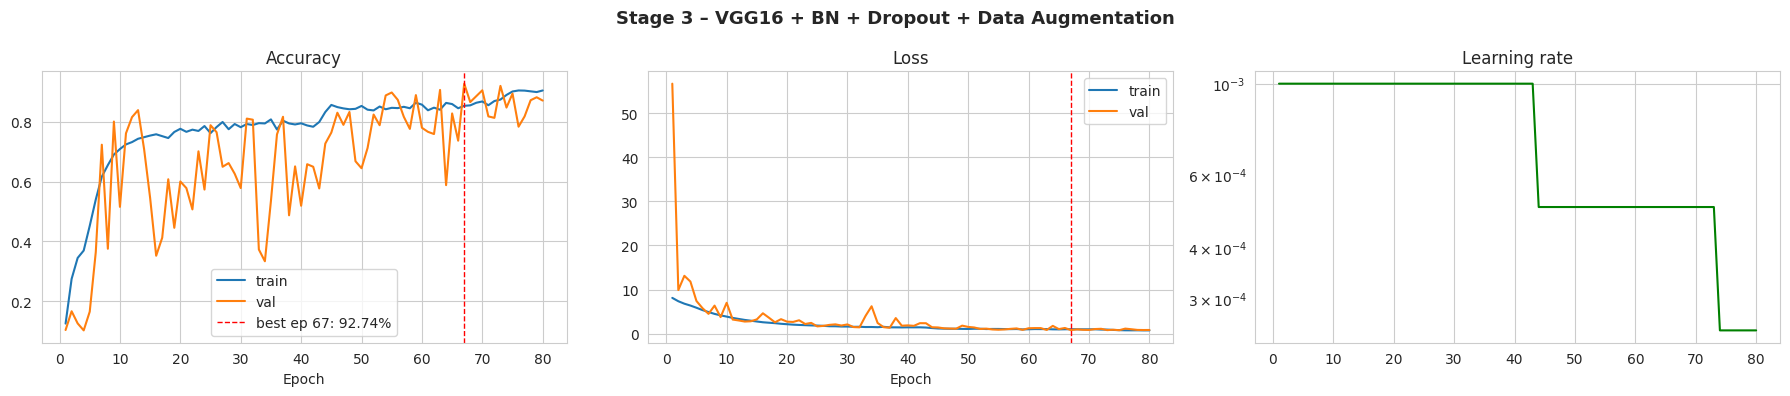

📊 KẾT QUẢ STAGE 3: VGG16 + BN + Dropout + Augmentation
  • Số tham số          : 16,047,178
  • Epoch tốt nhất      : 67/80
  • Thời gian train     : 7.0 phút (5.3s/epoch)
------------------------------------------------------------
  • Train Accuracy: 88.00% | Loss: 0.4089  (1819/2067)
  • Validation Accuracy: 92.74% | Loss: 0.3071  (754/813)
  • Label Book Accuracy: 82.69% | Loss: 0.5595  (43/52)
------------------------------------------------------------
  • Top-2 Acc  (Val / Label Book) : 97.17% / 88.46%
  • Macro-F1   (Val / Label Book) : 92.61% / 82.28%
  • Generalization gap (Train − Val): -4.74%
✅ Đã lưu trọng số mô hình tốt nhất: best_vgg16_stage3.weights.h5


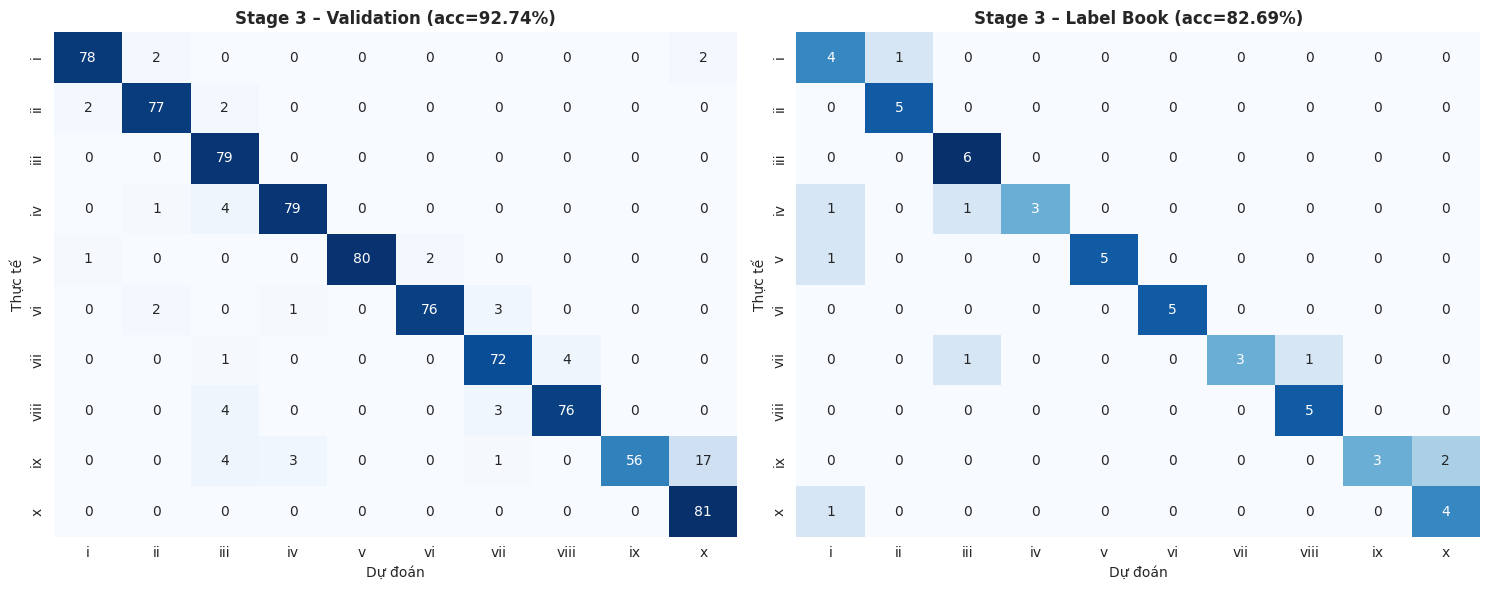

In [18]:
plot_history(hist_s3, "Stage 3 – VGG16 + BN + Dropout + Data Augmentation")
res_s3 = evaluate_stage(3, "VGG16 + BN + Dropout + Augmentation", model_s3, hist_s3, time_s3, ckpt_s3)
quick_report(model_s3, 3)

### 🔹 Stage 4 – Tối ưu hoá quá trình train (mô hình cuối cùng)
| Kỹ thuật | Tác dụng |
|---|---|
| **AdamW** (weight decay 1e-4) | Weight decay tách rời khỏi gradient → regularize tốt hơn Adam + L2 |
| **Warmup + Cosine Decay LR** | Khởi động êm, giảm LR mượt về cuối → hội tụ vào cực tiểu phẳng |
| **Label smoothing 0.1** | Tránh model quá tự tin, tổng quát hoá tốt hơn |
| **Class weights** | Bù mất cân bằng lớp |
| **EarlyStopping** (patience 25) | Dừng sớm khi không cải thiện |

In [19]:
set_seed()
tf.keras.backend.clear_session()

STAGE4_EPOCHS = 120
steps_per_epoch = int(train_raw.cardinality().numpy())
total_steps  = STAGE4_EPOCHS * steps_per_epoch
warmup_steps = 5 * steps_per_epoch

lr_schedule = optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4, decay_steps=total_steps - warmup_steps, alpha=0.01,
    warmup_target=1e-3, warmup_steps=warmup_steps,
)

# Class weights
y_train_int = np.concatenate([np.argmax(y.numpy(), 1) for _, y in train_eval_raw])
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train_int)
class_weights = dict(enumerate(cw))
print("⚖️  Class weights:", {CLASS_NAMES[k]: round(v, 3) for k, v in class_weights.items()})

class LRLogger(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        opt = self.model.optimizer
        logs["learning_rate"] = float(opt.learning_rate(opt.iterations)) if callable(opt.learning_rate) \
                                else float(opt.learning_rate)

model_s4 = build_vgg16(use_bn=True, dropout=0.5, l2=0.0, name="VGG16_stage4_final")

hist_s4, time_s4, ckpt_s4 = train_stage(
    stage_id=4, model=model_s4, train_data=train_aug_ds, epochs=STAGE4_EPOCHS,
    optimizer=optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
    loss_fn=losses.CategoricalCrossentropy(label_smoothing=0.1),
    class_weight=class_weights,
    extra_callbacks=[LRLogger(),
                     callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=25,
                                             restore_best_weights=True, verbose=1)],
)

⚖️  Class weights: {'i': np.float64(0.792), 'ii': np.float64(1.317), 'iii': np.float64(1.111), 'iv': np.float64(0.736), 'v': np.float64(1.055), 'vi': np.float64(1.142), 'vii': np.float64(1.071), 'viii': np.float64(1.039), 'ix': np.float64(0.883), 'x': np.float64(1.155)}
🚀 Bắt đầu train Stage 4 – 120 epochs tối đa
Epoch 1/120
65/65 - 33s - 508ms/step - accuracy: 0.1297 - loss: 2.7830 - top2_acc: 0.2467 - val_accuracy: 0.1095 - val_loss: 2.8584 - val_top2_acc: 0.1943 - learning_rate: 2.8000e-04
Epoch 2/120
65/65 - 5s - 74ms/step - accuracy: 0.2037 - loss: 2.5107 - top2_acc: 0.3483 - val_accuracy: 0.1058 - val_loss: 3.1615 - val_top2_acc: 0.2226 - learning_rate: 4.6000e-04
Epoch 3/120
65/65 - 5s - 80ms/step - accuracy: 0.3106 - loss: 2.1852 - top2_acc: 0.4833 - val_accuracy: 0.1205 - val_loss: 7.0191 - val_top2_acc: 0.2349 - learning_rate: 6.4000e-04
Epoch 4/120
65/65 - 5s - 83ms/step - accuracy: 0.4340 - loss: 1.8590 - top2_acc: 0.6386 - val_accuracy: 0.2079 - val_loss: 8.0245 - val_top2

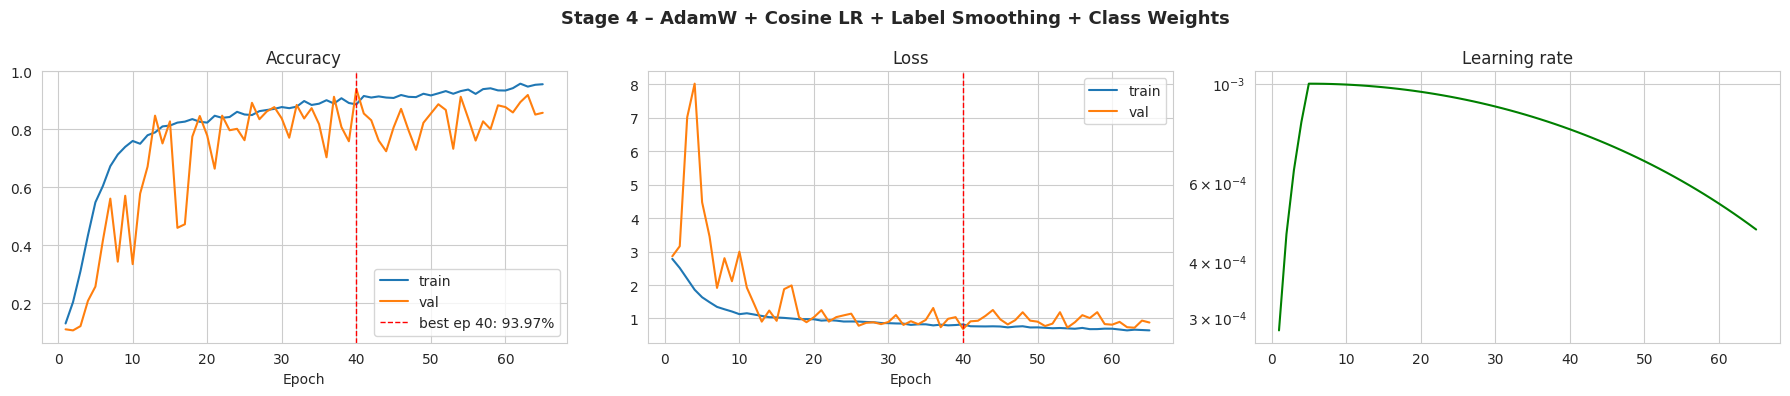

📊 KẾT QUẢ STAGE 4: VGG16 + BN + Aug + AdamW + CosineLR + LabelSmoothing
  • Số tham số          : 16,047,178
  • Epoch tốt nhất      : 40/65
  • Thời gian train     : 5.8 phút (5.4s/epoch)
------------------------------------------------------------
  • Train Accuracy: 93.42% | Loss: 0.2842  (1931/2067)
  • Validation Accuracy: 93.97% | Loss: 0.2751  (764/813)
  • Label Book Accuracy: 92.31% | Loss: 0.3863  (48/52)
------------------------------------------------------------
  • Top-2 Acc  (Val / Label Book) : 97.79% / 94.23%
  • Macro-F1   (Val / Label Book) : 93.96% / 92.29%
  • Generalization gap (Train − Val): -0.55%
✅ Đã lưu trọng số mô hình tốt nhất: best_vgg16_stage4.weights.h5


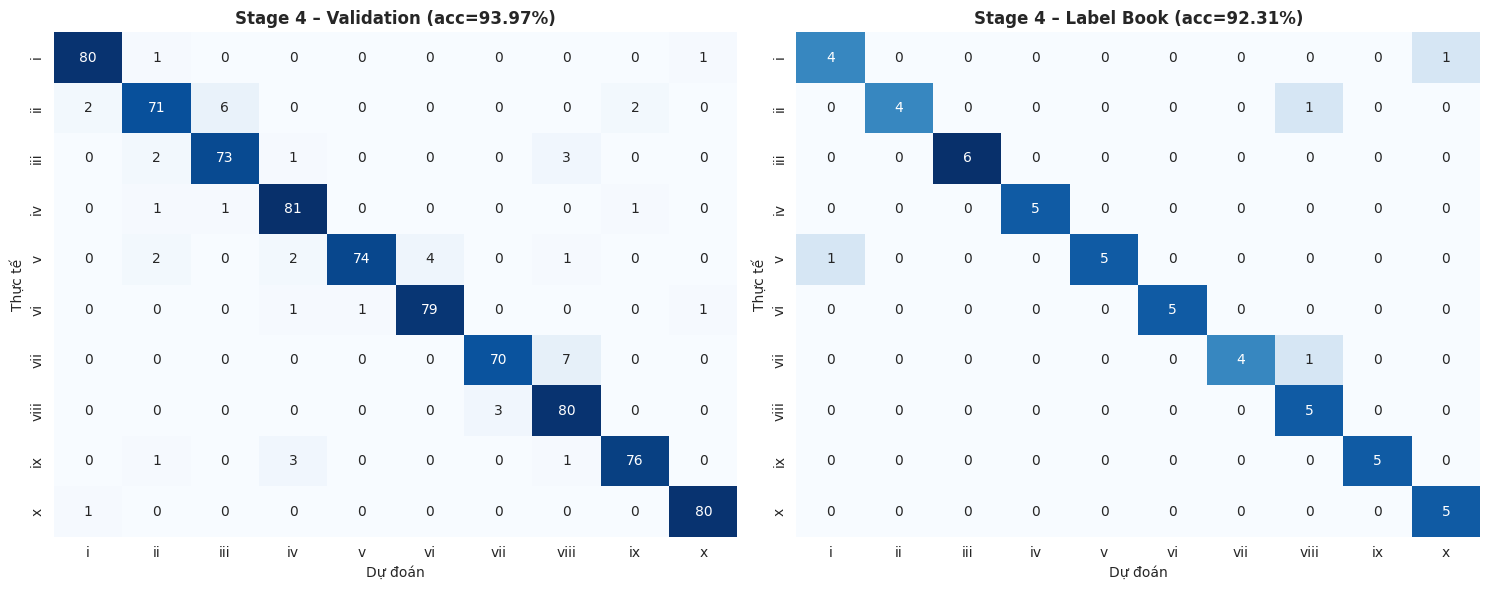

In [20]:
plot_history(hist_s4, "Stage 4 – AdamW + Cosine LR + Label Smoothing + Class Weights")
res_s4 = evaluate_stage(4, "VGG16 + BN + Aug + AdamW + CosineLR + LabelSmoothing", model_s4, hist_s4, time_s4, ckpt_s4)
quick_report(model_s4, 4)

---
## 8. 📈 So sánh kết quả các Stage

In [21]:
df_res = pd.DataFrame(RESULTS.values()).set_index("Stage")
pct_cols = ["Train Acc", "Val Acc", "Val Top2", "Val F1", "LB Acc", "LB Top2", "LB F1"]

df_show = df_res.copy()
for c in pct_cols: df_show[c] = (df_show[c] * 100).round(2)
for c in ["Train Loss", "Val Loss", "LB Loss"]: df_show[c] = df_show[c].round(4)
df_show["Δ Val vs Baseline"] = (df_show["Val Acc"] - df_show["Val Acc"].iloc[0]).round(2)
df_show["Δ LB vs Baseline"]  = (df_show["LB Acc"]  - df_show["LB Acc"].iloc[0]).round(2)

print("📋 BẢNG TỔNG HỢP KẾT QUẢ (accuracy tính theo %)")
display(df_show.drop(columns=["Weights"]).style
        .highlight_max(subset=["Val Acc", "LB Acc", "Val F1", "LB F1"], color="#b6e3b6")
        .highlight_min(subset=["Val Loss", "LB Loss"], color="#b6e3b6")
        .format(precision=2))
df_show.to_csv("stage_comparison.csv")
print("💾 Đã lưu bảng: stage_comparison.csv")

📋 BẢNG TỔNG HỢP KẾT QUẢ (accuracy tính theo %)


,Mô tả,Params,Best epoch,Epochs chạy,Time (phút),Train Acc,Train Loss,Val Acc,Val Loss,Val Top2,Val F1,LB Acc,LB Loss,LB Top2,LB F1,Δ Val vs Baseline,Δ LB vs Baseline
Stage,,,,,,,,,,,,,,,,,
Stage 1,Baseline VGG16 (no BN / no Dropout / no Aug),16030410,37,40,3.80,100.00,0.00,89.05,0.63,95.33,89.03,86.54,1.10,94.23,87.23,0.00,0.00
Stage 2,VGG16 + BN + Dropout + L2,16047178,46,50,4.70,95.45,0.21,88.56,0.46,94.59,88.78,82.69,0.57,90.38,83.76,-0.49,-3.85
Stage 3,VGG16 + BN + Dropout + Augmentation,16047178,67,80,7.00,88.00,0.41,92.74,0.31,97.17,92.61,82.69,0.56,88.46,82.28,3.69,-3.85
Stage 4,VGG16 + BN + Aug + AdamW + CosineLR + LabelSmoothing,16047178,40,65,5.80,93.42,0.28,93.97,0.28,97.79,93.96,92.31,0.39,94.23,92.29,4.92,5.77


💾 Đã lưu bảng: stage_comparison.csv


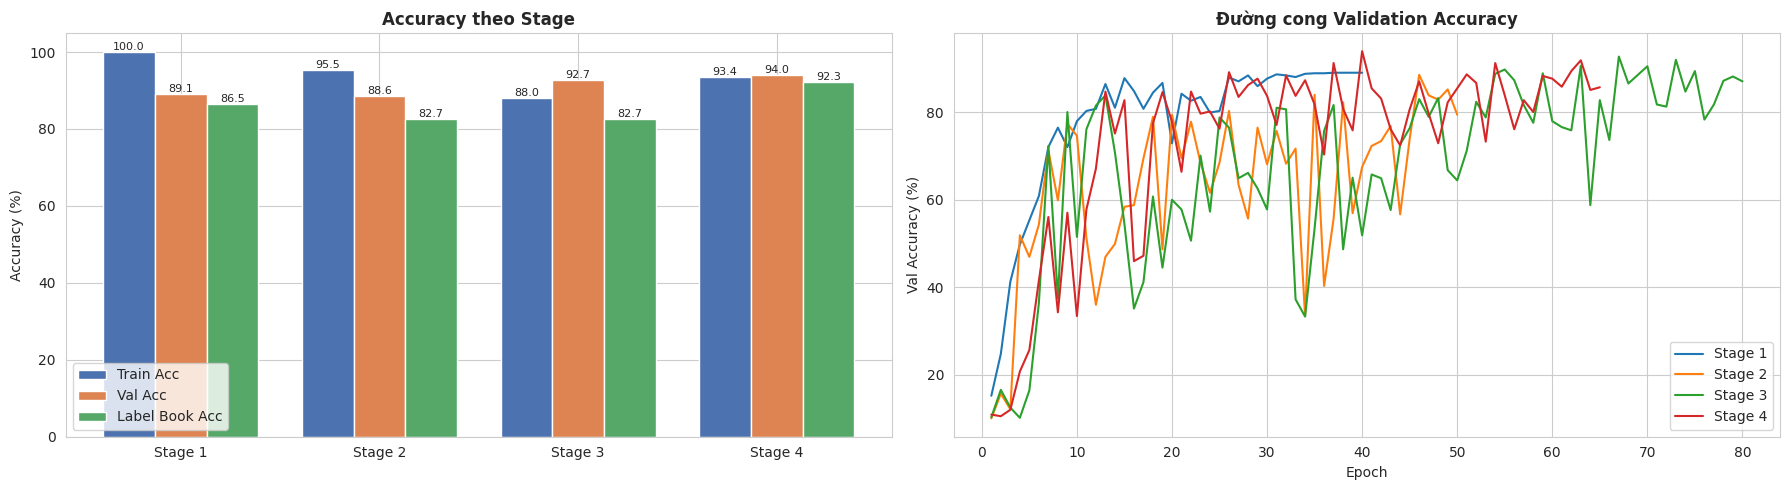

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Accuracy theo stage
x = np.arange(len(df_res)); w = 0.26
for i, (col, color) in enumerate([("Train Acc", "#4C72B0"), ("Val Acc", "#DD8452"), ("LB Acc", "#55A868")]):
    bars = axes[0].bar(x + (i - 1) * w, df_res[col] * 100, w, label=col.replace("LB", "Label Book"), color=color)
    axes[0].bar_label(bars, fmt="%.1f", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(df_res.index); axes[0].set_ylim(0, 105)
axes[0].set_ylabel("Accuracy (%)"); axes[0].set_title("Accuracy theo Stage", fontweight="bold"); axes[0].legend()

# Val accuracy curves
for sid, h in HISTORIES.items():
    axes[1].plot(np.arange(1, len(h["val_accuracy"]) + 1), np.array(h["val_accuracy"]) * 100, label=f"Stage {sid}")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Accuracy (%)")
axes[1].set_title("Đường cong Validation Accuracy", fontweight="bold"); axes[1].legend()
plt.tight_layout(); plt.show()

---
## 9. 🔬 Phân tích chi tiết mô hình tốt nhất
Chọn stage có **Validation Accuracy cao nhất** (nếu bằng nhau → ưu tiên Label Book Accuracy).

In [23]:
STAGE_MODELS = {1: model_s1, 2: model_s2, 3: model_s3, 4: model_s4}
best_stage = max(RESULTS, key=lambda s: (RESULTS[s]["Val Acc"], RESULTS[s]["LB Acc"]))
best_model = STAGE_MODELS[best_stage]
best_model.load_weights(RESULTS[best_stage]["Weights"])
print(f"🏆 Mô hình tốt nhất: Stage {best_stage} – {RESULTS[best_stage]['Mô tả']}")

yt_val, yp_val, X_val = predict_ds(best_model, val_ds, return_images=True)
yt_lb,  yp_lb,  X_lb  = predict_ds(best_model, lb_ds,  return_images=True)
yt_tr,  yp_tr         = predict_ds(best_model, train_eval_ds)
pred_val, pred_lb, pred_tr = yp_val.argmax(1), yp_lb.argmax(1), yp_tr.argmax(1)

for name, yt, yp in [("TRAIN", yt_tr, yp_tr), ("VALIDATION", yt_val, yp_val), ("LABEL BOOK", yt_lb, yp_lb)]:
    m = metrics_from_pred(yt, yp)
    print(f"  {name:<11}: Acc = {m['acc']*100:6.2f}% | Loss = {m['loss']:.4f} | "
          f"Top-2 = {m['top2']*100:6.2f}% | Macro-F1 = {m['f1_macro']*100:6.2f}% | {m['n_correct']}/{m['n_total']}")

🏆 Mô hình tốt nhất: Stage 4 – VGG16 + BN + Aug + AdamW + CosineLR + LabelSmoothing
  TRAIN      : Acc =  93.42% | Loss = 0.2842 | Top-2 =  96.90% | Macro-F1 =  93.20% | 1931/2067
  VALIDATION : Acc =  93.97% | Loss = 0.2751 | Top-2 =  97.79% | Macro-F1 =  93.96% | 764/813
  LABEL BOOK : Acc =  92.31% | Loss = 0.3863 | Top-2 =  94.23% | Macro-F1 =  92.29% | 48/52


### 9.1 Classification report (Precision / Recall / F1 theo lớp)

In [24]:
for name, yt, yp in [("VALIDATION", yt_val, pred_val), ("LABEL BOOK", yt_lb, pred_lb)]:
    print("=" * 62)
    print(f"📄 CLASSIFICATION REPORT – {name}")
    print("=" * 62)
    print(classification_report(yt, yp, labels=range(NUM_CLASSES), target_names=CLASS_NAMES, digits=4, zero_division=0))

📄 CLASSIFICATION REPORT – VALIDATION
              precision    recall  f1-score   support

           i     0.9639    0.9756    0.9697        82
          ii     0.9103    0.8765    0.8931        81
         iii     0.9125    0.9241    0.9182        79
          iv     0.9205    0.9643    0.9419        84
           v     0.9867    0.8916    0.9367        83
          vi     0.9518    0.9634    0.9576        82
         vii     0.9589    0.9091    0.9333        77
        viii     0.8696    0.9639    0.9143        83
          ix     0.9620    0.9383    0.9500        81
           x     0.9756    0.9877    0.9816        81

    accuracy                         0.9397       813
   macro avg     0.9412    0.9394    0.9396       813
weighted avg     0.9410    0.9397    0.9397       813

📄 CLASSIFICATION REPORT – LABEL BOOK
              precision    recall  f1-score   support

           i     0.8000    0.8000    0.8000         5
          ii     1.0000    0.8000    0.8889         5
    

### 9.2 Accuracy theo từng lớp (per-class accuracy)

,Train (%),Val (%),Label Book (%),Val đúng/tổng,LB đúng/tổng
I,96.170000,97.560000,80.000000,80/82,4/5
II,85.990000,87.650000,80.000000,71/81,4/5
III,88.170000,92.410000,100.000000,73/79,6/6
IV,95.730000,96.430000,100.000000,81/84,5/5
V,88.780000,89.160000,83.330000,74/83,5/6
VI,96.130000,96.340000,100.000000,79/82,5/5
VII,92.750000,90.910000,80.000000,70/77,4/5
VIII,94.970000,96.390000,100.000000,80/83,5/5
IX,95.300000,93.830000,100.000000,76/81,5/5
X,96.650000,98.770000,100.000000,80/81,5/5


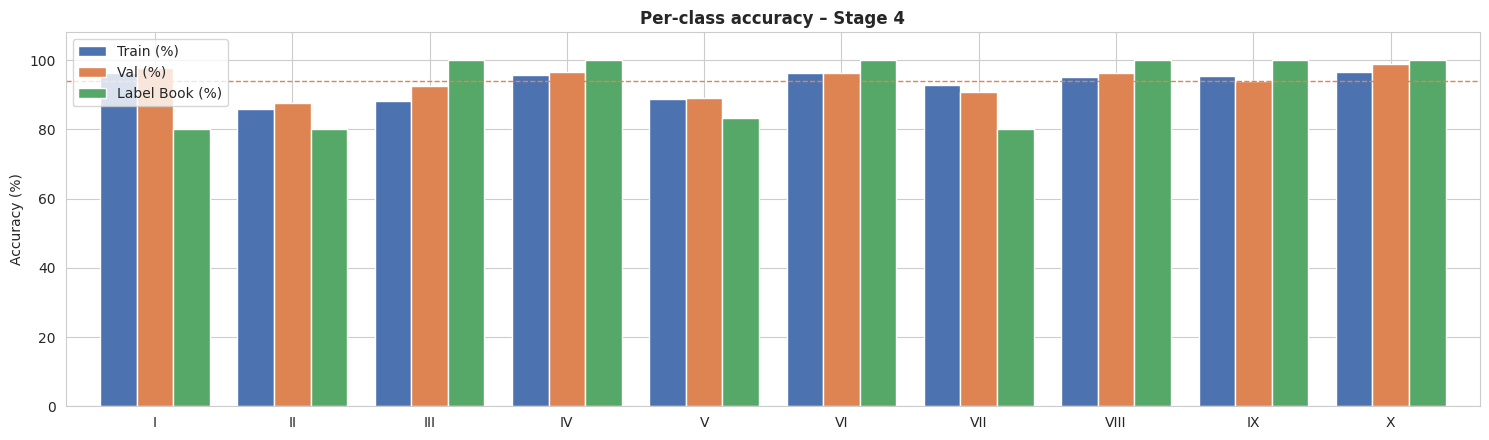

In [25]:
def per_class_acc(yt, yp):
    return [((yp == yt) & (yt == k)).sum() / max((yt == k).sum(), 1) for k in range(NUM_CLASSES)]

df_pc = pd.DataFrame({
    "Train (%)":      np.round(np.array(per_class_acc(yt_tr,  pred_tr))  * 100, 2),
    "Val (%)":        np.round(np.array(per_class_acc(yt_val, pred_val)) * 100, 2),
    "Label Book (%)": np.round(np.array(per_class_acc(yt_lb,  pred_lb))  * 100, 2),
    "Val đúng/tổng":  [f"{((pred_val==yt_val)&(yt_val==k)).sum()}/{(yt_val==k).sum()}" for k in range(NUM_CLASSES)],
    "LB đúng/tổng":   [f"{((pred_lb==yt_lb)&(yt_lb==k)).sum()}/{(yt_lb==k).sum()}" for k in range(NUM_CLASSES)],
}, index=[c.upper() for c in CLASS_NAMES])
display(df_pc.style.background_gradient(cmap="RdYlGn", subset=["Train (%)", "Val (%)", "Label Book (%)"], vmin=50, vmax=100))

ax = df_pc[["Train (%)", "Val (%)", "Label Book (%)"]].plot.bar(figsize=(15, 4.5), width=0.8, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylim(0, 108); ax.set_ylabel("Accuracy (%)"); ax.set_title(f"Per-class accuracy – Stage {best_stage}", fontweight="bold")
ax.axhline(RESULTS[best_stage]["Val Acc"] * 100, color="#DD8452", ls="--", lw=1)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 9.3 Confusion matrix (số lượng & chuẩn hoá)

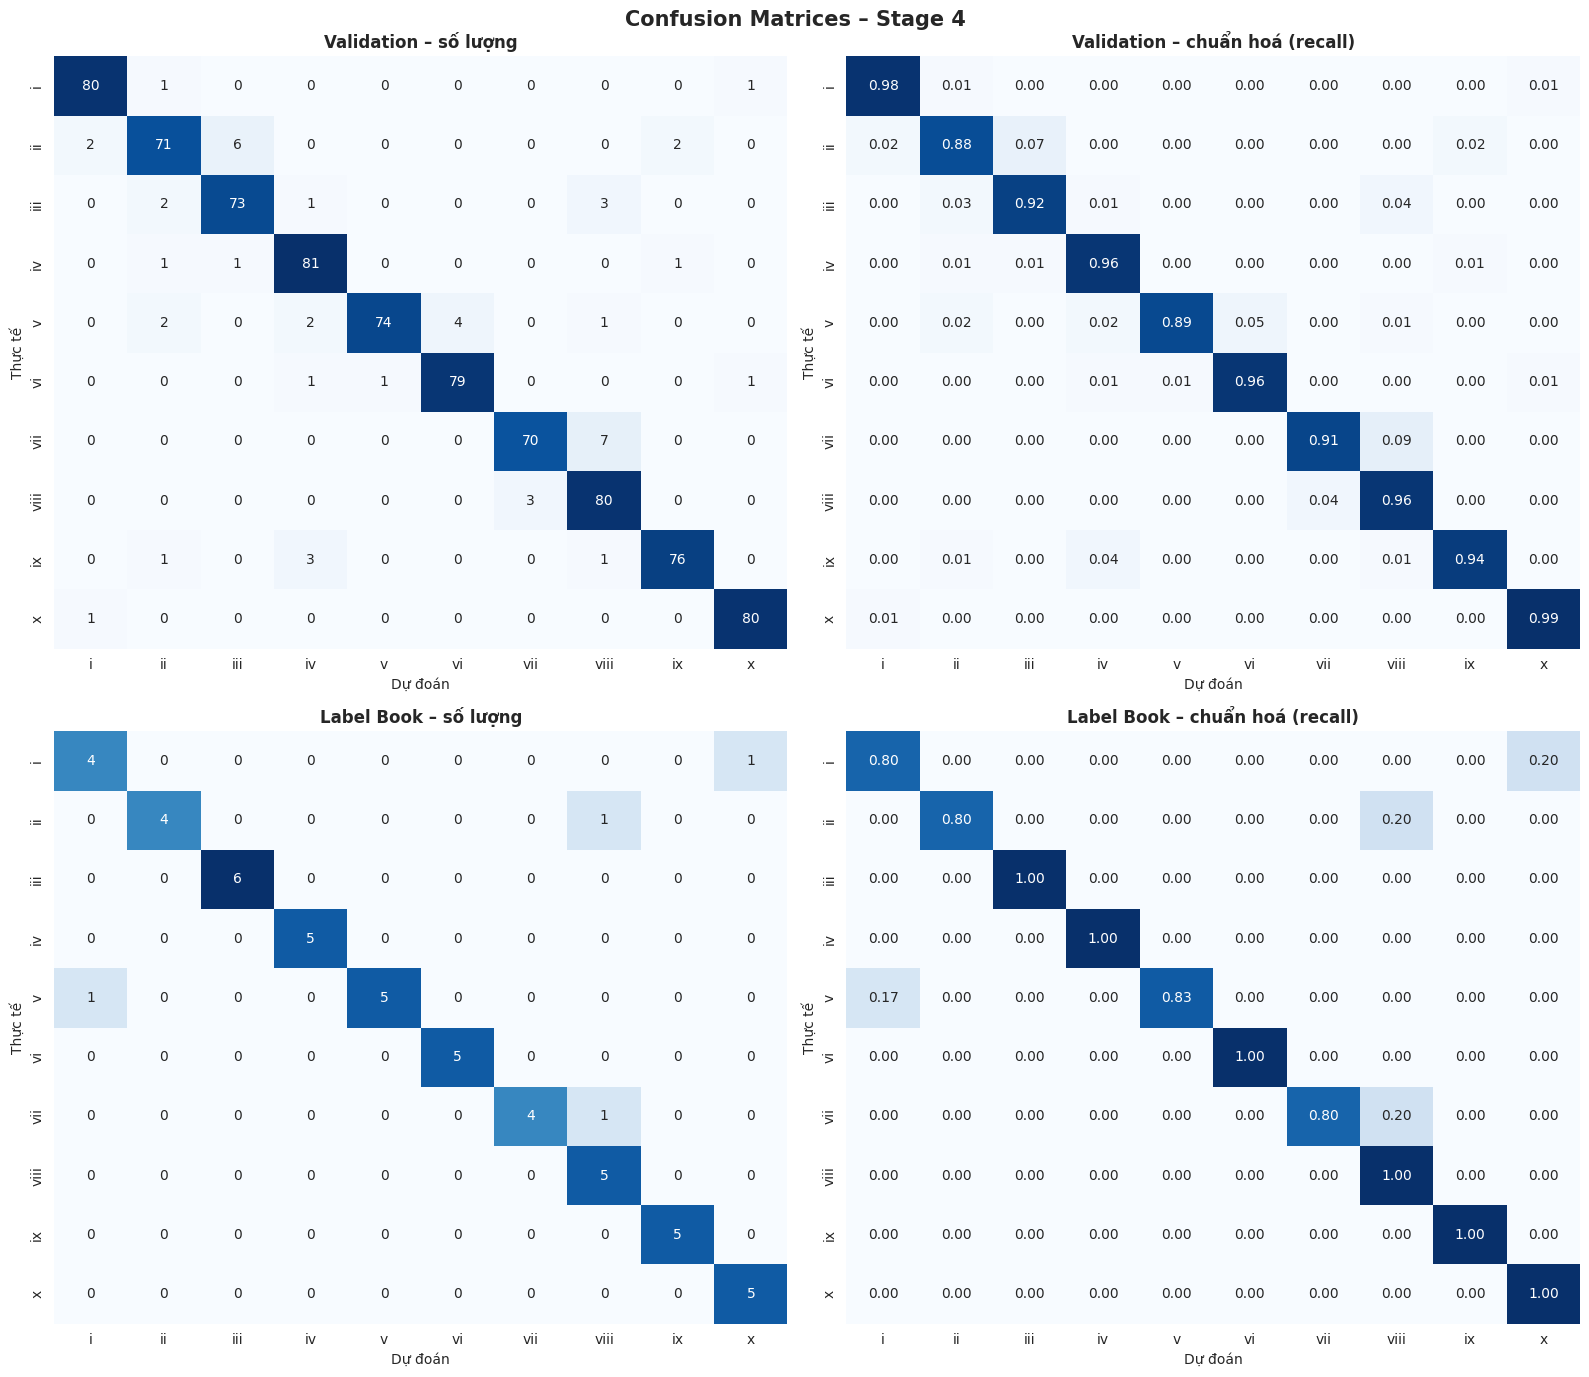

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
plot_confusion(yt_val, pred_val, "Validation – số lượng",       ax=axes[0, 0])
plot_confusion(yt_val, pred_val, "Validation – chuẩn hoá (recall)", normalize=True, ax=axes[0, 1])
plot_confusion(yt_lb,  pred_lb,  "Label Book – số lượng",       ax=axes[1, 0])
plot_confusion(yt_lb,  pred_lb,  "Label Book – chuẩn hoá (recall)", normalize=True, ax=axes[1, 1])
plt.suptitle(f"Confusion Matrices – Stage {best_stage}", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

### 9.4 Các cặp lớp hay bị nhầm lẫn nhất

In [27]:
cm_val = confusion_matrix(yt_val, pred_val, labels=range(NUM_CLASSES))
pairs = [(CLASS_NAMES[i].upper(), CLASS_NAMES[j].upper(), cm_val[i, j], cm_val[i, j] / cm_val[i].sum() * 100)
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm_val[i, j] > 0]
df_conf = (pd.DataFrame(pairs, columns=["Thực tế", "Dự đoán nhầm thành", "Số ảnh", "% của lớp"])
             .sort_values("Số ảnh", ascending=False).reset_index(drop=True))
df_conf["% của lớp"] = df_conf["% của lớp"].round(2)
print(f"🔎 Top cặp nhầm lẫn trên VALIDATION (tổng {len(yt_val) - (pred_val == yt_val).sum()} ảnh sai):")
display(df_conf.head(10))

🔎 Top cặp nhầm lẫn trên VALIDATION (tổng 49 ảnh sai):


,Thực tế,Dự đoán nhầm thành,Số ảnh,% của lớp
0,VII,VIII,7,9.09
1,II,III,6,7.41
2,V,VI,4,4.82
3,III,VIII,3,3.80
4,IX,IV,3,3.70
5,VIII,VII,3,3.61
6,II,IX,2,2.47
7,II,I,2,2.47
8,V,IV,2,2.41
9,V,II,2,2.41


### 9.5 Phân bố độ tự tin (confidence) của dự đoán đúng vs sai

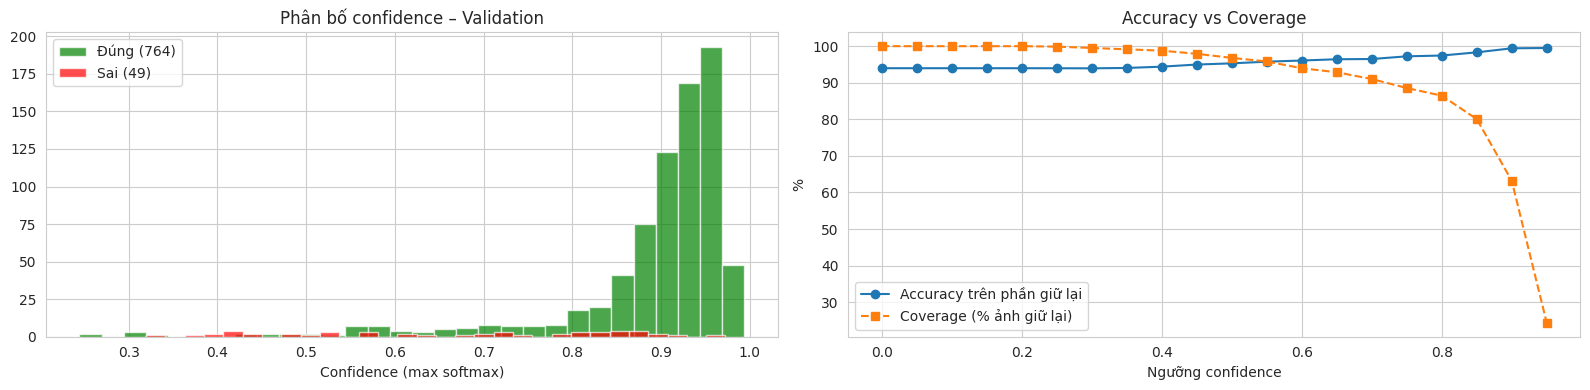

Confidence TB – đúng: 0.8920 | sai: 0.6679


In [28]:
conf_val = yp_val.max(1)
correct  = pred_val == yt_val
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].hist(conf_val[correct],  bins=30, alpha=0.7, label=f"Đúng ({correct.sum()})",  color="green")
axes[0].hist(conf_val[~correct], bins=30, alpha=0.7, label=f"Sai ({(~correct).sum()})", color="red")
axes[0].set_xlabel("Confidence (max softmax)"); axes[0].set_title("Phân bố confidence – Validation"); axes[0].legend()

# Accuracy theo ngưỡng confidence
ths = np.linspace(0, 0.95, 20)
cov = [(conf_val >= t).mean() * 100 for t in ths]
acc = [correct[conf_val >= t].mean() * 100 if (conf_val >= t).any() else np.nan for t in ths]
axes[1].plot(ths, acc, "o-", label="Accuracy trên phần giữ lại")
axes[1].plot(ths, cov, "s--", label="Coverage (% ảnh giữ lại)")
axes[1].set_xlabel("Ngưỡng confidence"); axes[1].set_ylabel("%"); axes[1].set_title("Accuracy vs Coverage"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Confidence TB – đúng: {conf_val[correct].mean():.4f} | sai: {conf_val[~correct].mean() if (~correct).any() else float('nan'):.4f}")

### 9.6 Ảnh bị dự đoán sai

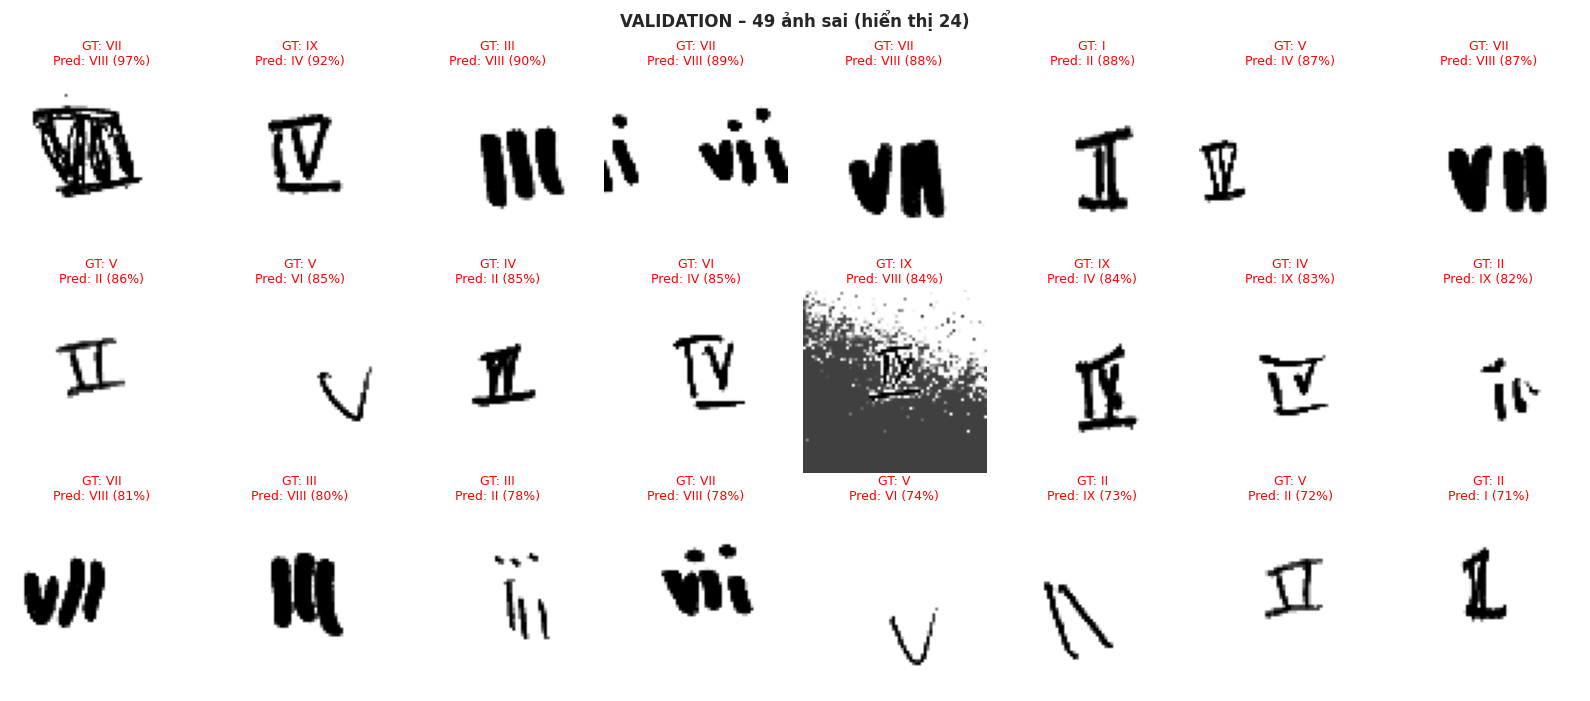

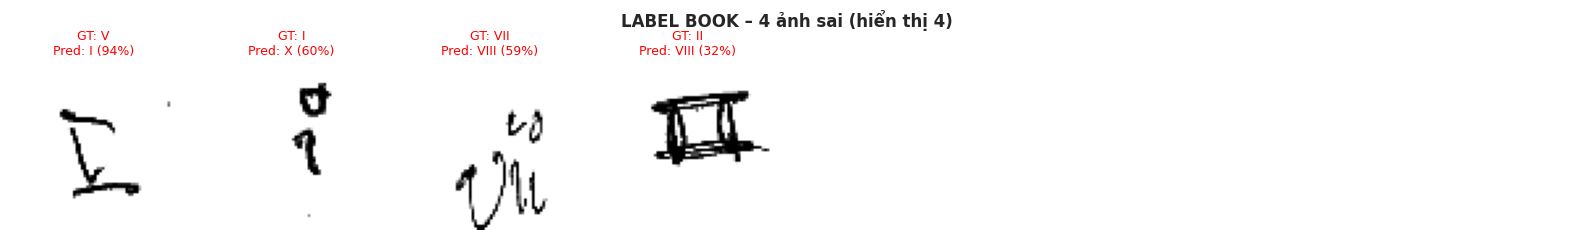

In [29]:
def show_errors(X, yt, yp_prob, title, max_n=24, cols=8):
    pred = yp_prob.argmax(1)
    idx = np.where(pred != yt)[0]
    idx = idx[np.argsort(-yp_prob[idx].max(1))][:max_n]       # sai nhưng tự tin nhất lên trước
    if len(idx) == 0:
        print(f"🎉 {title}: không có ảnh nào bị dự đoán sai!"); return
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.4))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, idx):
        ax.imshow(X[i, ..., 0], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"GT: {CLASS_NAMES[yt[i]].upper()}\nPred: {CLASS_NAMES[pred[i]].upper()} ({yp_prob[i].max()*100:.0f}%)",
                     fontsize=9, color="red")
    plt.suptitle(f"{title} – {len(np.where(pred != yt)[0])} ảnh sai (hiển thị {len(idx)})", fontweight="bold")
    plt.tight_layout(); plt.show()

show_errors(X_val, yt_val, yp_val, "VALIDATION")
show_errors(X_lb,  yt_lb,  yp_lb,  "LABEL BOOK")

### 9.7 Dự đoán trên toàn bộ Label Book

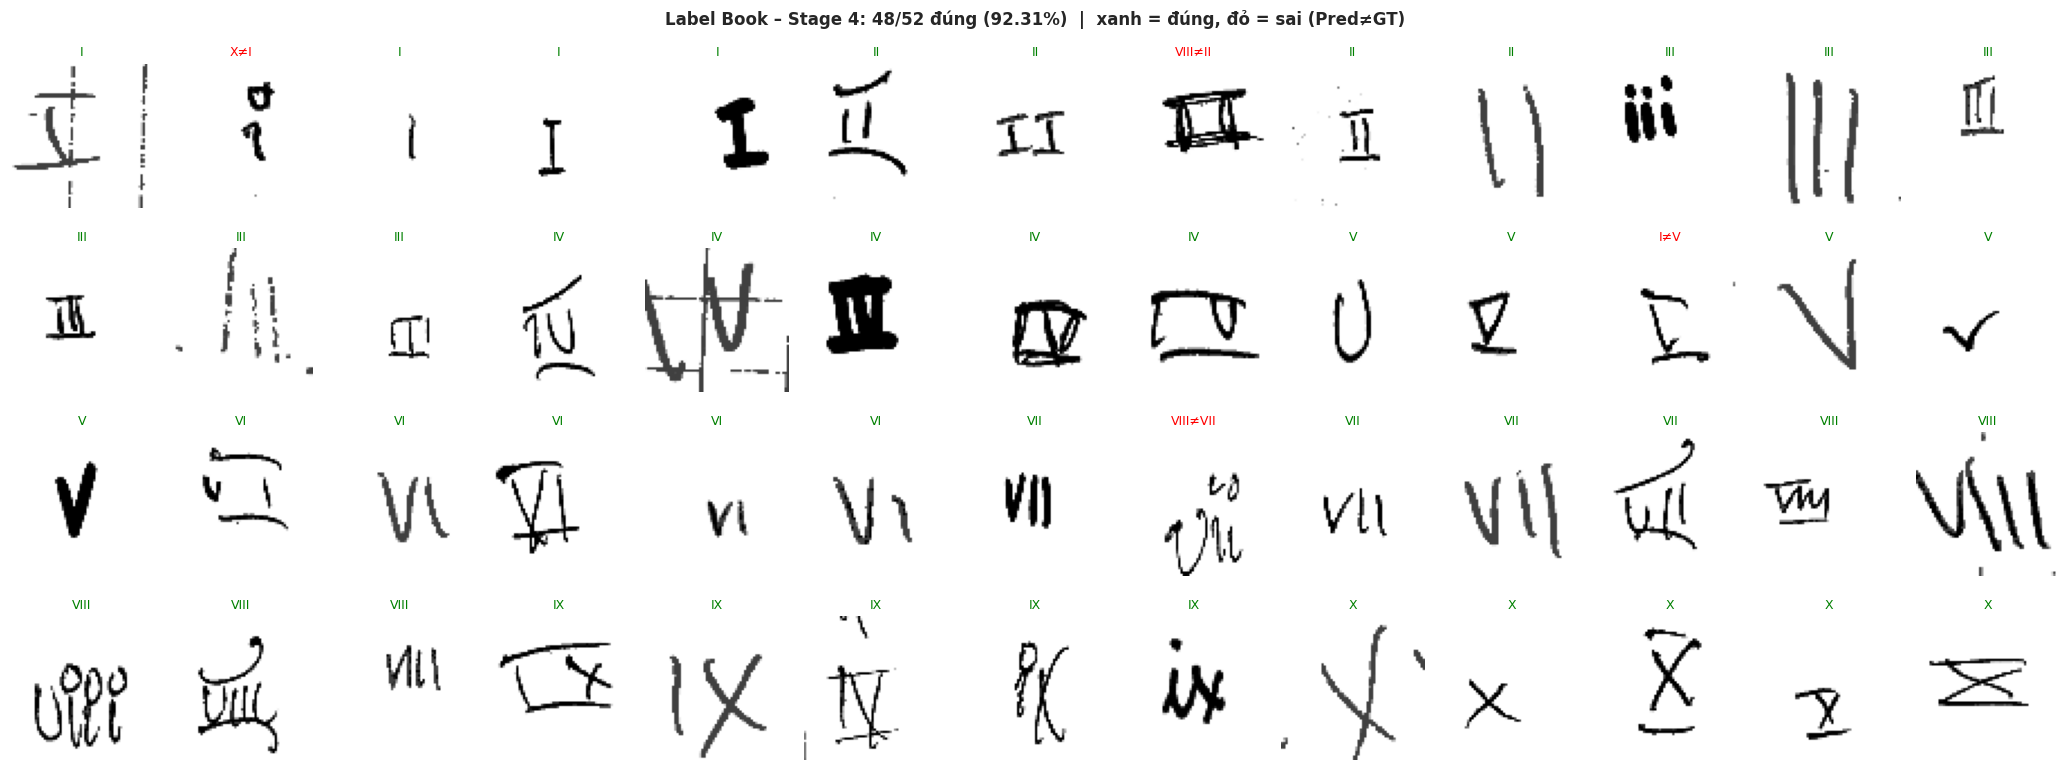

In [30]:
cols = 13
rows = int(np.ceil(len(yt_lb) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 2.0))
axes = np.array(axes).reshape(-1)
for ax in axes: ax.axis("off")
for k in range(len(yt_lb)):
    ok = pred_lb[k] == yt_lb[k]
    axes[k].imshow(X_lb[k, ..., 0], cmap="gray", vmin=0, vmax=255)
    axes[k].set_title(f"{CLASS_NAMES[pred_lb[k]].upper()}" + ("" if ok else f"≠{CLASS_NAMES[yt_lb[k]].upper()}"),
                      fontsize=9, color="green" if ok else "red")
plt.suptitle(f"Label Book – Stage {best_stage}: {(pred_lb == yt_lb).sum()}/{len(yt_lb)} đúng "
             f"({(pred_lb == yt_lb).mean()*100:.2f}%)  |  xanh = đúng, đỏ = sai (Pred≠GT)", fontweight="bold")
plt.tight_layout(); plt.show()

---
## 10. 🧪 Inference trên ảnh bất kỳ & lưu mô hình

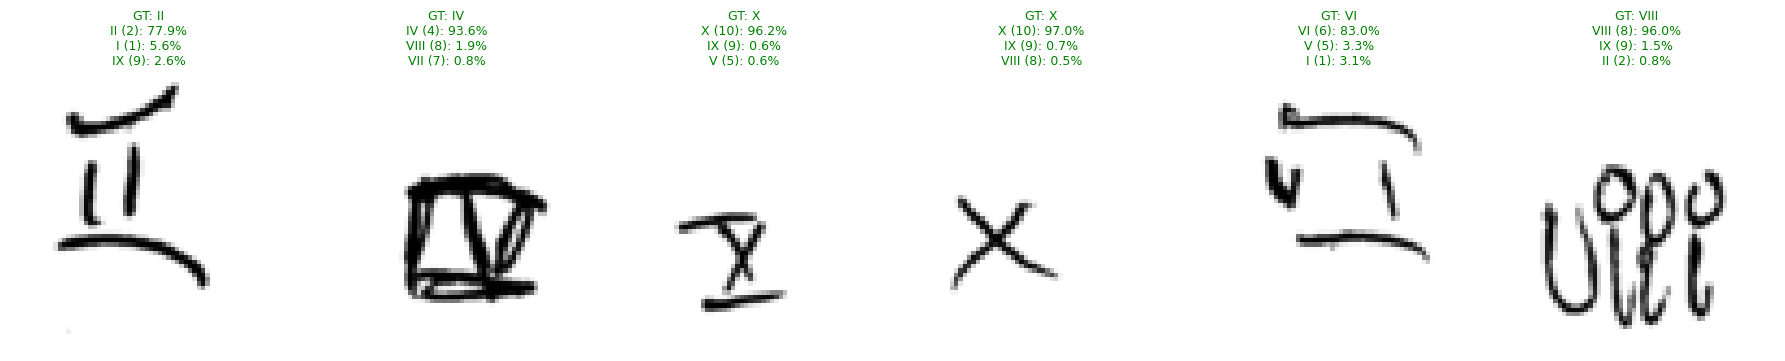

In [31]:
def predict_image(model, path, top_k=3):
    img = Image.open(path).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    x = np.asarray(img, dtype=np.float32)[None, ..., None]
    prob = model.predict(x, verbose=0)[0]
    top = np.argsort(prob)[::-1][:top_k]
    return [(CLASS_NAMES[i].upper(), ROMAN_TO_INT[CLASS_NAMES[i]], float(prob[i])) for i in top], img

demo_files = random.sample(glob.glob(os.path.join(LABEL_BOOK_DIR, "*", "*.png")), 6)
fig, axes = plt.subplots(1, len(demo_files), figsize=(3 * len(demo_files), 3.4))
for ax, f in zip(axes, demo_files):
    preds, img = predict_image(best_model, f)
    gt = os.path.basename(os.path.dirname(f)).upper()
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ax.set_title(f"GT: {gt}\n" + "\n".join(f"{r} ({n}): {p*100:.1f}%" for r, n, p in preds),
                 fontsize=9, color="green" if preds[0][0] == gt else "red")
plt.tight_layout(); plt.show()

In [32]:
# Lưu mô hình tốt nhất (kiến trúc + trọng số) và trọng số riêng
FINAL_MODEL_PATH   = "vgg16_roman_numerals_final.keras"
FINAL_WEIGHTS_PATH = f"best_vgg16_stage{best_stage}.weights.h5"
best_model.save(FINAL_MODEL_PATH)

print("💾 Các file đã lưu:")
for f in sorted(glob.glob("best_vgg16_stage*.weights.h5")) + [FINAL_MODEL_PATH, "stage_comparison.csv"] \
         + sorted(glob.glob("history_stage*.csv")):
    if os.path.exists(f):
        print(f"   • {f:<40} {os.path.getsize(f)/1e6:8.2f} MB")

# Tải về máy (chỉ trên Colab)
if IN_COLAB:
    from google.colab import files
    # files.download(FINAL_MODEL_PATH)   # bỏ comment để tải về

💾 Các file đã lưu:
   • best_vgg16_stage1.weights.h5               192.49 MB
   • best_vgg16_stage2.weights.h5               192.67 MB
   • best_vgg16_stage3.weights.h5               192.67 MB
   • best_vgg16_stage4.weights.h5               192.67 MB
   • vgg16_roman_numerals_final.keras           192.72 MB
   • stage_comparison.csv                         0.00 MB
   • history_stage1.csv                           0.00 MB
   • history_stage2.csv                           0.01 MB
   • history_stage3.csv                           0.01 MB
   • history_stage4.csv                           0.01 MB


In [33]:
# ======================== TỔNG KẾT CUỐI CÙNG ========================
r = RESULTS[best_stage]
print("=" * 60)
print(f"🏆 MÔ HÌNH CUỐI CÙNG: VGG16 (from scratch) – Stage {best_stage}")
print(f"   {r['Mô tả']}")
print("=" * 60)
print(f"  • Train Accuracy: {r['Train Acc']*100:.2f}% | Loss: {r['Train Loss']:.4f}")
print(f"  • Validation Accuracy: {r['Val Acc']*100:.2f}% | Loss: {r['Val Loss']:.4f}")
print(f"  • Label Book Accuracy: {r['LB Acc']*100:.2f}% | Loss: {r['LB Loss']:.4f}")
print(f"  • Cải thiện so với Baseline (Val / LB): "
      f"{(r['Val Acc'] - RESULTS[1]['Val Acc'])*100:+.2f}% / {(r['LB Acc'] - RESULTS[1]['LB Acc'])*100:+.2f}%")
print("=" * 60)
print(f"✅ Đã lưu trọng số mô hình tốt nhất: {r['Weights']}")

🏆 MÔ HÌNH CUỐI CÙNG: VGG16 (from scratch) – Stage 4
   VGG16 + BN + Aug + AdamW + CosineLR + LabelSmoothing
  • Train Accuracy: 93.42% | Loss: 0.2842
  • Validation Accuracy: 93.97% | Loss: 0.2751
  • Label Book Accuracy: 92.31% | Loss: 0.3863
  • Cải thiện so với Baseline (Val / LB): +4.92% / +5.77%
✅ Đã lưu trọng số mô hình tốt nhất: best_vgg16_stage4.weights.h5


---
## 11. 📝 Kết luận

**Những điểm chính**
1. **VGG16 tự xây dựng** (13 Conv + 3 FC) hoạt động tốt trên ảnh 64×64 grayscale mà không cần pretrained weights hay `tf.keras.applications`.
2. **Baseline (Stage 1)** – VGG16 không BN rất sâu nên khó train từ đầu, hội tụ chậm và overfit nhanh trên tập dữ liệu nhỏ.
3. **BatchNorm + Dropout (Stage 2)** giúp hội tụ nhanh hơn rõ rệt, ổn định gradient.
4. **Data augmentation (Stage 3)** là yếu tố quan trọng nhất để tăng accuracy trên **Label Book** (dữ liệu chưa từng thấy) — đúng tinh thần *Data-Centric AI*.
5. **Stage 4** (AdamW + Cosine LR + Label smoothing + Class weights) tinh chỉnh thêm, cho kết quả tốt nhất.

**Các lớp dễ nhầm:** thường là các cặp có cấu trúc gần giống nhau như `II ↔ III`, `VII ↔ VIII`, `IV ↔ VI`, `IX ↔ X`… (xem mục 9.4).

**Hướng phát triển**
- Làm sạch nhãn sai / loại ảnh nhiễu trong tập train (data-centric).
- Sinh thêm dữ liệu (tổng train + val ≤ 10.000 ảnh theo luật cuộc thi).
- Thử resize giữ tỉ lệ (pad trắng), tăng kích thước ảnh lên 96×96, hoặc dùng Global Average Pooling thay Flatten.
- Ensemble nhiều checkpoint / Test-Time Augmentation.

In [34]:
import shutil
from google.colab import files

# Đường dẫn thư mục cần nén và file đích
folder_to_zip = "/content/deeplearningai-data-centric-competition"
zip_file = "/content/deeplearningai_project.zip"

print("📦 Đang nén dữ liệu... (Vui lòng đợi vài phút do các file weights khá lớn)")
shutil.make_archive(zip_file.replace('.zip', ''), 'zip', folder_to_zip)
print(f"✅ Đã nén xong thành: {zip_file}")

print("⬇️ Đang tải về máy...")
files.download(zip_file)


📦 Đang nén dữ liệu... (Vui lòng đợi vài phút do các file weights khá lớn)
✅ Đã nén xong thành: /content/deeplearningai_project.zip
⬇️ Đang tải về máy...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>